# PaySim Financial Fraud Detection and Investigation
## Project Overview

This project applies SQL, Python, data analysis, feature engineering, and machine learning to investigate potentially suspicious financial transactions using the PaySim synthetic mobile money transaction dataset. The primary objective is to identify patterns associated with fraud-labelled transactions and develop a model that can support financial crime detection and investigation.

The project follows a structured analytical workflow, beginning with data ingestion and exploration, followed by transaction pattern investigation, feature engineering, and Random Forest model development. Model predictions are then examined to identify suspicious transactions, assess false positives and false negatives, and understand the characteristics associated with potential fraud.

The model is evaluated using both random train-test splitting and chronological validation to examine its ability to identify fraud-labelled transactions in a later simulated period. The project emphasizes that machine learning predictions should support human investigation rather than serve as independent proof of fraudulent activity.

## Project Objective

The objective of this project is to apply data analytics and machine learning techniques to identify potentially suspicious financial transactions and support data-driven financial crime investigation.

Specifically, the project aims to:

1. Explore and understand transaction patterns associated with fraud-labelled and legitimate transactions.

2. Use SQL and Python to investigate transaction behaviour and engineer relevant features for fraud analysis.

3. Develop a Random Forest classification model to identify potentially fraudulent transactions.

4. Evaluate model performance using precision, recall, F1-score, confusion matrices, and chronological validation.

5. Examine model-generated alerts, including false positives and false negatives, to understand their implications for further investigation.

6. Demonstrate how machine learning can support human-led financial crime detection and investigation.

In [6]:
!pip install scikit-learn

In [7]:

# I am initializing my project environment by importing pandas for tabular data manipulation, DuckDB for memory-safe SQL querying, sklearn.ensemble for building robust predictive models, and sklearn.model_selection for clean cross-validation and data splitting.
import pandas as pd
import duckdb
from sklearn import ensemble
from sklearn import model_selection

In [8]:
import kagglehub
import duckdb

# 1. Fetch the dataset folder from Kaggle and fix Windows path slashes
folder_path = kagglehub.dataset_download("ealaxi/paysim1").replace("\\", "/")

# 2. Set the specific file name you want to load
file_name = "PS_20174392719_1491204439457_log.csv"

# 3. Combine the folder and file name into a complete file path
file_path = f"{folder_path}/{file_name}"

# 4. Read the full dataset into a Pandas DataFrame via DuckDB
df_rel = duckdb.sql(
    f"SELECT * FROM read_csv('{file_path}')"
).df()

# Preview the original transaction dataset
display(df_rel.head(10))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.0,0.00,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.0,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.0,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.0,0.00,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.0,0.00,0,0
5,1,PAYMENT,7817.71,C90045638,53860.00,46042.29,M573487274,0.0,0.00,0,0
6,1,PAYMENT,7107.77,C154988899,183195.00,176087.23,M408069119,0.0,0.00,0,0
7,1,PAYMENT,7861.64,C1912850431,176087.23,168225.59,M633326333,0.0,0.00,0,0
8,1,PAYMENT,4024.36,C1265012928,2671.00,0.00,M1176932104,0.0,0.00,0,0
9,1,DEBIT,5337.77,C712410124,41720.00,36382.23,C195600860,41898.0,40348.79,0,0


### 2 Data Type Conversion

At this stage, we are converting the columns into appropriate data types based on the nature and purpose of each variable. Numerical transaction fields will retain numerical formats, account identifiers will be treated as strings, transaction types will be categorical variables, and fraud indicators will be represented as integers. Proper data types improve memory management, data consistency, and the accuracy of subsequent feature engineering and machine learning operations. The original dataset will remain unchanged as we perform these transformations on a separate working copy.

In [9]:
# Create a working copy of the original dataset

df_clean = df_rel.copy()

# Convert columns into appropriate data types

df_clean = df_clean.astype({
    'step': 'int32',
    'type': 'category',
    'amount': 'float64',
    'nameOrig': 'string',
    'oldbalanceOrg': 'float64',
    'newbalanceOrig': 'float64',
    'nameDest': 'string',
    'oldbalanceDest': 'float64',
    'newbalanceDest': 'float64',
    'isFraud': 'int8',
    'isFlaggedFraud': 'int8'
})

# Inspect updated data types

print(df_clean.dtypes)

step                 int32
type              category
amount             float64
nameOrig            string
oldbalanceOrg      float64
newbalanceOrig     float64
nameDest            string
oldbalanceDest     float64
newbalanceDest     float64
isFraud               int8
isFlaggedFraud        int8
dtype: object


### 3 Missing Value Assessment

In this stage, we examine the dataset for missing values across all columns. Identifying missing observations is important because incomplete transaction records can affect statistical analysis, feature engineering, and model performance. We will assess both the number and proportion of missing values in each column before deciding whether any treatment is necessary. No records will be removed or modified during this assessment.

In [10]:
# Assess missing values in each column

missing_summary = pd.DataFrame({
    'Missing Values': df_clean.isnull().sum(),
    'Missing Percentage': df_clean.isnull().mean() * 100
})

display(missing_summary)

,Missing Values,Missing Percentage
step,0,0.0
type,0,0.0
amount,0,0.0
nameOrig,0,0.0
oldbalanceOrg,0,0.0
newbalanceOrig,0,0.0
nameDest,0,0.0
oldbalanceDest,0,0.0
newbalanceDest,0,0.0
isFraud,0,0.0


### 3 Duplicate Record Assessment

We use DuckDB SQL to identify fully duplicated transaction records across all 11 columns. Duplicate records can distort transaction counts, statistical analysis, and model training. We will first quantify the duplicates and their proportion before deciding whether removal is appropriate. The original dataset will remain unchanged during this assessment.

In [11]:
# Assess duplicate transaction records using DuckDB

duplicate_summary = duckdb.sql("""
    SELECT
        COUNT(*) AS total_records,
        COUNT(*) - COUNT(DISTINCT (
            step, type, amount, nameOrig,
            oldbalanceOrg, newbalanceOrig,
            nameDest, oldbalanceDest,
            newbalanceDest, isFraud, isFlaggedFraud
        )) AS duplicate_records
    FROM df_rel
""").df()

duplicate_summary['duplicate_percentage'] = (
    duplicate_summary['duplicate_records'] /
    duplicate_summary['total_records'] * 100
)

display(duplicate_summary)

,total_records,duplicate_records,duplicate_percentage
0,6362620,0,0.0


### 4 Data Value and Consistency Assessment

In this stage, we use DuckDB SQL to examine the distribution and validity of transaction values. We investigate transaction categories, numerical ranges, and fraud indicators to identify unusual or inconsistent observations. This assessment helps us distinguish legitimate transaction behavior from potential data-quality issues before applying any cleaning or transformation rules. The original records will remain unchanged during this process.

In [12]:
# Assess numerical ranges and potential invalid values

value_assessment = duckdb.sql("""
    SELECT
        MIN(amount) AS min_amount,
        MAX(amount) AS max_amount,
        COUNT(*) FILTER (WHERE amount < 0) AS negative_amounts,

        MIN(oldbalanceOrg) AS min_origin_balance,
        MIN(oldbalanceDest) AS min_destination_balance,

        COUNT(*) FILTER (
            WHERE oldbalanceOrg < 0 OR newbalanceOrig < 0
               OR oldbalanceDest < 0 OR newbalanceDest < 0
        ) AS negative_balance_records,

        COUNT(*) FILTER (WHERE isFraud NOT IN (0, 1)) AS invalid_fraud_labels,

        COUNT(*) FILTER (WHERE isFlaggedFraud NOT IN (0, 1)) AS invalid_flags

    FROM df_rel
""").df()

display(value_assessment)

,min_amount,max_amount,negative_amounts,min_origin_balance,min_destination_balance,negative_balance_records,invalid_fraud_labels,invalid_flags
0,0.0,92445516.64,0,0.0,0.0,0,0,0


### 5 Transaction Type Distribution

This stage examines the distribution of transaction types within the PaySim dataset. Understanding the frequency of each transaction category helps establish the dataset's behavioral composition and identify which transaction types dominate the available records. This information will also guide our subsequent fraud analysis and feature engineering decisions.

In [13]:
# Examine transaction type distribution

transaction_distribution = duckdb.sql("""
    SELECT
        type,
        COUNT(*) AS transaction_count,
        ROUND(
            COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (),
            2
        ) AS percentage
    FROM df_rel
    GROUP BY type
    ORDER BY transaction_count DESC
""").df()

display(transaction_distribution)

,type,transaction_count,percentage
0,CASH_OUT,2237500,35.17
1,PAYMENT,2151495,33.81
2,CASH_IN,1399284,21.99
3,TRANSFER,532909,8.38
4,DEBIT,41432,0.65


## 7 Fraud Class Distribution

This stage examines the distribution of legitimate and fraudulent transactions using the target variable, isFraud. Since financial fraud datasets typically contain significantly fewer fraudulent transactions than legitimate ones, understanding this imbalance is essential. We will calculate the number and percentage of observations in each class to establish the baseline fraud prevalence and guide our model evaluation strategy.

In [14]:
# Examine fraud and legitimate transaction distribution

fraud_distribution = duckdb.sql("""
    SELECT
        isFraud,
        COUNT(*) AS transaction_count,
        ROUND(
            COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (),
            4
        ) AS percentage
    FROM df_rel
    GROUP BY isFraud
    ORDER BY isFraud
""").df()

display(fraud_distribution)

,isFraud,transaction_count,percentage
0,0,6354407,99.8709
1,1,8213,0.1291


### Fraud Distribution Across Transaction Types

In this stage, we investigate how fraudulent transactions are distributed across different transaction categories. We calculate the total number of transactions, fraudulent transactions, and fraud rate for each transaction type. This analysis helps identify transaction categories that may exhibit higher fraud exposure and provides useful insights for subsequent feature engineering. We distinguish between the volume of transactions and the proportion of transactions identified as fraudulent.

In [15]:
# Analyze fraud distribution across transaction types

fraud_by_type = duckdb.sql("""
    SELECT
        type,
        COUNT(*) AS total_transactions,
        SUM(isFraud) AS fraudulent_transactions,
        ROUND(
            SUM(isFraud) * 100.0 / COUNT(*), 4
        ) AS fraud_rate
    FROM df_rel
    GROUP BY type
    ORDER BY fraud_rate DESC
""").df()

display(fraud_by_type)

,type,total_transactions,fraudulent_transactions,fraud_rate
0,TRANSFER,532909,4097.0,0.7688
1,CASH_OUT,2237500,4116.0,0.1840
2,DEBIT,41432,0.0,0.0000
3,PAYMENT,2151495,0.0,0.0000
4,CASH_IN,1399284,0.0,0.0000


### Existing Fraud Flag Assessment

In this stage, we investigate the relationship between the existing `isFlaggedFraud` indicator and the actual fraud labels stored in `isFraud`. The purpose is to understand how effectively the dataset's existing flag identifies fraudulent transactions and whether it contains information that could introduce target leakage into our machine learning models. We will examine the distribution of flagged and unflagged transactions across both fraud classes without modifying the original records.

In [16]:
# Examine the relationship between existing fraud flags and actual fraud

flag_assessment = duckdb.sql("""
    SELECT
        isFlaggedFraud,
        isFraud,
        COUNT(*) AS transaction_count
    FROM df_rel
    GROUP BY isFlaggedFraud, isFraud
    ORDER BY isFlaggedFraud, isFraud
""").df()

display(flag_assessment)

,isFlaggedFraud,isFraud,transaction_count
0,0,0,6354407
1,0,1,8197
2,1,1,16


### Existing Fraud Flag Assessment

In this stage, we investigate the relationship between the existing `isFlaggedFraud` indicator and the actual fraud labels stored in `isFraud`. The purpose is to understand how effectively the dataset's existing flag identifies fraudulent transactions and whether it contains information that could introduce target leakage into our machine learning models. We will examine the distribution of flagged and unflagged transactions across both fraud classes without modifying the original records.

In [17]:
# Examine the relationship between existing fraud flags and actual fraud

flag_assessment = duckdb.sql("""
    SELECT
        isFlaggedFraud,
        isFraud,
        COUNT(*) AS transaction_count
    FROM df_rel
    GROUP BY isFlaggedFraud, isFraud
    ORDER BY isFlaggedFraud, isFraud
""").df()

display(flag_assessment)

,isFlaggedFraud,isFraud,transaction_count
0,0,0,6354407
1,0,1,8197
2,1,1,16


### Transaction Amount Analysis by Fraud Status

This analysis compares the monetary characteristics of legitimate and fraudulent transactions. We examine transaction counts, average amounts, median amounts, and minimum and maximum values for each fraud category. The objective is to understand whether fraudulent transactions exhibit distinct monetary patterns and whether transaction amount could contribute useful information to our fraud detection features.

In [18]:
# Compare transaction amounts by fraud status

amount_analysis = duckdb.sql("""
    SELECT
        isFraud,
        COUNT(*) AS transaction_count,
        ROUND(AVG(amount), 2) AS average_amount,
        ROUND(MEDIAN(amount), 2) AS median_amount,
        ROUND(MIN(amount), 2) AS minimum_amount,
        ROUND(MAX(amount), 2) AS maximum_amount
    FROM df_rel
    GROUP BY isFraud
    ORDER BY isFraud
""").df()

display(amount_analysis)

,isFraud,transaction_count,average_amount,median_amount,minimum_amount,maximum_amount
0,0,6354407,178197.04,74684.72,0.01,92445516.64
1,1,8213,1467967.30,441423.44,0.00,10000000.00


### Transaction Amount Distribution Analysis

This analysis examines transaction amounts at different percentiles for legitimate and fraudulent transactions. While averages and medians provide an initial comparison, percentile analysis helps us understand the distribution, spread, and concentration of transaction values. We also investigate zero-value transactions to determine whether they occur in fraudulent or legitimate records. These findings will help establish whether transaction amount and unusual monetary behavior should be incorporated into our engineered features.

In [19]:
# Examine transaction amount percentiles by fraud status

amount_percentiles = duckdb.sql("""
    SELECT
        isFraud,
        ROUND(quantile_cont(amount, 0.25), 2) AS percentile_25,
        ROUND(quantile_cont(amount, 0.50), 2) AS percentile_50,
        ROUND(quantile_cont(amount, 0.75), 2) AS percentile_75,
        ROUND(quantile_cont(amount, 0.90), 2) AS percentile_90,
        ROUND(quantile_cont(amount, 0.95), 2) AS percentile_95,
        ROUND(quantile_cont(amount, 0.99), 2) AS percentile_99,
        COUNT(*) FILTER (WHERE amount = 0) AS zero_amount_transactions
    FROM df_rel
    GROUP BY isFraud
    ORDER BY isFraud
""").df()

display(amount_percentiles)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,isFraud,percentile_25,percentile_50,percentile_75,percentile_90,percentile_95,percentile_99,zero_amount_transactions
0,0,13368.40,74684.72,208364.76,364373.44,515610.42,1586064.17,0
1,1,127091.33,441423.44,1517771.48,4521723.51,8006429.04,10000000.00,16


### Temporal Transaction Analysis

This stage investigates the temporal distribution of transactions using the step variable in the PaySim dataset. We examine transaction activity across time and compare legitimate and fraudulent transaction patterns. Understanding when fraudulent transactions occur can help identify periods of unusual activity and guide the development of time-based and transaction-velocity features. This analysis will also inform how we construct chronological training and testing datasets to prevent future information from influencing past predictions.

In [20]:
# Examine transaction activity across time

temporal_analysis = duckdb.sql("""
    SELECT
        step,
        COUNT(*) AS total_transactions,
        SUM(isFraud) AS fraudulent_transactions,
        ROUND(
            SUM(isFraud) * 100.0 / COUNT(*), 4
        ) AS fraud_rate
    FROM df_rel
    GROUP BY step
    ORDER BY step
""").df()

display(temporal_analysis.head(20))

,step,total_transactions,fraudulent_transactions,fraud_rate
0,1,2708,16.0,0.5908
1,2,1014,8.0,0.7890
2,3,552,4.0,0.7246
3,4,565,10.0,1.7699
4,5,665,6.0,0.9023
5,6,1660,22.0,1.3253
6,7,6837,12.0,0.1755
7,8,21097,12.0,0.0569
8,9,37628,19.0,0.0505
9,10,35991,11.0,0.0306


### Daily Transaction and Fraud Activity

This analysis groups transactions into 24-step periods to examine how transaction activity and fraudulent behavior change throughout the simulation. We calculate total transaction volume, fraudulent transaction counts, and fraud rates for each period. This helps identify whether fraud activity is concentrated during particular periods or remains relatively consistent over time. The findings will guide the development of time-based and transaction-velocity features.

In [21]:
# Examine transaction and fraud activity across 24-step periods

daily_temporal_analysis = duckdb.sql("""
    SELECT
        CAST(FLOOR((step - 1) / 24) + 1 AS INTEGER) AS simulation_day,
        COUNT(*) AS total_transactions,
        SUM(isFraud) AS fraudulent_transactions,
        ROUND(
            SUM(isFraud) * 100.0 / COUNT(*), 4
        ) AS fraud_rate
    FROM df_rel
    GROUP BY simulation_day
    ORDER BY simulation_day
""").df()

display(daily_temporal_analysis)

,simulation_day,total_transactions,fraudulent_transactions,fraud_rate
0,1,574255,271.0,0.0472
1,2,455238,309.0,0.0679
2,3,1070,310.0,28.9720
3,4,28240,262.0,0.9278
4,5,9789,252.0,2.5743
5,6,441005,228.0,0.0517
6,7,420583,272.0,0.0647
7,8,449637,278.0,0.0618
8,9,417919,255.0,0.0610
9,10,392945,282.0,0.0718


### Investigation of Unusual Temporal Fraud Activity

Following the daily temporal analysis, Day 3 displayed an unusually high fraud rate despite having significantly fewer transactions than surrounding periods. This investigation examines individual transaction steps within that simulated day to determine whether fraudulent activity is concentrated within particular time intervals. The objective is to distinguish genuine temporal patterns from isolated activity spikes before developing time-based fraud detection features.

In [22]:
# Investigate individual transaction steps within Day 3

day3_analysis = duckdb.sql("""
    SELECT
        step,
        COUNT(*) AS total_transactions,
        SUM(isFraud) AS fraudulent_transactions,
        ROUND(
            SUM(isFraud) * 100.0 / COUNT(*), 2
        ) AS fraud_rate
    FROM df_rel
    WHERE step BETWEEN 49 AND 72
    GROUP BY step
    ORDER BY step
""").df()

display(day3_analysis)

,step,total_transactions,fraudulent_transactions,fraud_rate
0,49,764,4.0,0.52
1,50,6,6.0,100.00
2,51,14,14.0,100.00
3,52,8,8.0,100.00
4,53,10,10.0,100.00
5,54,4,4.0,100.00
6,55,12,12.0,100.00
7,56,18,18.0,100.00
8,57,6,6.0,100.00
9,58,20,20.0,100.00


### Detailed Investigation of Day 3 Fraud Concentration

This investigation examines the distribution of legitimate and fraudulent transactions throughout the third simulated day. We focus on transaction counts and fraud proportions across individual time steps to determine whether the unusually high daily fraud rate is driven by a sustained pattern or a small number of concentrated intervals. This analysis will help us assess the predictive relevance of temporal variables while avoiding conclusions based on small transaction volumes.

In [23]:
# Examine legitimate and fraudulent transactions across Day 3

day3_detailed = duckdb.sql("""
    SELECT
        step,
        COUNT(*) AS total_transactions,
        SUM(isFraud) AS fraudulent_transactions,
        COUNT(*) - SUM(isFraud) AS legitimate_transactions,
        ROUND(
            SUM(isFraud) * 100.0 / COUNT(*), 2
        ) AS fraud_rate
    FROM df_rel
    WHERE step BETWEEN 49 AND 72
    GROUP BY step
    ORDER BY step
""").df()

display(day3_detailed)

,step,total_transactions,fraudulent_transactions,legitimate_transactions,fraud_rate
0,49,764,4.0,760.0,0.52
1,50,6,6.0,0.0,100.00
2,51,14,14.0,0.0,100.00
3,52,8,8.0,0.0,100.00
4,53,10,10.0,0.0,100.00
5,54,4,4.0,0.0,100.00
6,55,12,12.0,0.0,100.00
7,56,18,18.0,0.0,100.00
8,57,6,6.0,0.0,100.00
9,58,20,20.0,0.0,100.00


### Temporal Fraud Concentration Assessment

This analysis examines the distribution of fraud across all simulation time steps. We classify each time step according to whether it contains only fraudulent transactions, only legitimate transactions, or a mixture of both. The objective is to determine whether the unusual concentration observed during Day 3 is an isolated simulation pattern or part of a broader temporal structure. This investigation is important for identifying potential temporal leakage and designing reliable chronological validation strategies.

In [24]:
# Classify simulation steps by their fraud composition

step_pattern = duckdb.sql("""
    SELECT
        step,
        COUNT(*) AS total_transactions,
        SUM(isFraud) AS fraudulent_transactions,

        CASE
            WHEN SUM(isFraud) = COUNT(*) THEN 'Fraud Only'
            WHEN SUM(isFraud) = 0 THEN 'Legitimate Only'
            ELSE 'Mixed'
        END AS step_category

    FROM df_rel
    GROUP BY step
""").df()

step_summary = duckdb.sql("""
    SELECT
        step_category,
        COUNT(*) AS number_of_steps,
        SUM(total_transactions) AS total_transactions,
        SUM(fraudulent_transactions) AS fraudulent_transactions
    FROM step_pattern
    GROUP BY step_category
    ORDER BY number_of_steps DESC
""").df()

display(step_summary)

,step_category,number_of_steps,total_transactions,fraudulent_transactions
0,Mixed,421,6325216.0,4593.0
1,Fraud Only,320,3620.0,3620.0
2,Legitimate Only,2,33784.0,0.0


### Consecutive Fraud-Only Time Step Analysis

This investigation examines the sequence of simulation steps containing exclusively fraudulent transactions. We identify the beginning and ending points of consecutive fraud-only periods and measure their duration. The objective is to understand whether fraudulent activity occurs in isolated intervals or concentrated sequences. These findings will help us assess temporal dependencies and potential leakage risks when designing chronological training and testing strategies.

In [25]:
# Identify consecutive fraud-only periods

fraud_only_sequences = duckdb.sql("""
    WITH step_status AS (
        SELECT
            step,
            CASE
                WHEN SUM(isFraud) = COUNT(*) THEN 1
                ELSE 0
            END AS fraud_only
        FROM df_rel
        GROUP BY step
    ),

    step_groups AS (
        SELECT
            step,
            fraud_only,
            step - ROW_NUMBER() OVER (
                PARTITION BY fraud_only
                ORDER BY step
            ) AS sequence_group
        FROM step_status
    )

    SELECT
        MIN(step) AS start_step,
        MAX(step) AS end_step,
        COUNT(*) AS consecutive_steps,
        fraud_only
    FROM step_groups
    WHERE fraud_only = 1
    GROUP BY sequence_group, fraud_only
    ORDER BY consecutive_steps DESC
""").df()

display(fraud_only_sequences.head(20))

,start_step,end_step,consecutive_steps,fraud_only
0,50,92,43,1
1,719,743,25,1
2,98,118,21,1
3,622,629,8,1
4,556,562,7,1
5,218,224,7,1
6,315,320,6,1
7,602,607,6,1
8,387,392,6,1
9,650,655,6,1


### Transaction Type Composition During Fraud-Only Periods

This investigation examines the transaction types occurring during simulation steps containing exclusively fraudulent transactions. The objective is to determine whether these periods are dominated by specific transaction categories, particularly TRANSFER and CASH_OUT. Understanding this relationship will help distinguish transaction-level behavioral patterns from artificial temporal patterns introduced by the PaySim simulation process.

In [26]:
# Examine transaction types within fraud-only simulation steps

fraud_only_types = duckdb.sql("""
    WITH fraud_only_steps AS (
        SELECT step
        FROM df_rel
        GROUP BY step
        HAVING SUM(isFraud) = COUNT(*)
    )

    SELECT
        type,
        COUNT(*) AS transaction_count,
        COUNT(DISTINCT step) AS active_steps
    FROM df_rel
    WHERE step IN (
        SELECT step FROM fraud_only_steps
    )
    GROUP BY type
    ORDER BY transaction_count DESC
""").df()

display(fraud_only_types)

,type,transaction_count,active_steps
0,TRANSFER,1810,320
1,CASH_OUT,1810,320


### Account Balance Movement Analysis

This analysis examines how originating and destination account balances change during legitimate and fraudulent transactions. We compare the average opening and closing balances, as well as the differences between them, across both fraud categories. The objective is to understand whether fraudulent transactions exhibit distinct balance movement patterns and identify potential opportunities for engineering balance-based features. All calculations will be performed using DuckDB SQL without modifying the original dataset.

In [27]:
# Analyze account balance movements by fraud status

balance_analysis = duckdb.sql("""
    SELECT
        isFraud,
        COUNT(*) AS transaction_count,

        ROUND(AVG(oldbalanceOrg), 2) AS avg_origin_old_balance,
        ROUND(AVG(newbalanceOrig), 2) AS avg_origin_new_balance,

        ROUND(AVG(oldbalanceDest), 2) AS avg_destination_old_balance,
        ROUND(AVG(newbalanceDest), 2) AS avg_destination_new_balance,

        ROUND(AVG(oldbalanceOrg - newbalanceOrig), 2)
            AS avg_origin_balance_change,

        ROUND(AVG(newbalanceDest - oldbalanceDest), 2)
            AS avg_destination_balance_change

    FROM df_rel
    GROUP BY isFraud
    ORDER BY isFraud
""").df()

print(balance_analysis)

   isFraud  transaction_count  avg_origin_old_balance  avg_origin_new_balance  \
0        0            6354407               832828.71               855970.23   
1        1               8213              1649667.61               192392.63   

   avg_destination_old_balance  avg_destination_new_balance  \
0                   1101420.87                   1224925.68   
1                    544249.62                   1279707.62   

   avg_origin_balance_change  avg_destination_balance_change  
0                  -23141.52                       123504.81  
1                 1457274.97                       735458.00  


### Transaction Balance Reconciliation Analysis

This investigation evaluates whether recorded account balance movements are consistent with transaction amounts. We calculate the expected closing balances for originating and destination accounts and compare them with the actual recorded balances. The resulting discrepancies help identify transactions where account movements do not reconcile with the reported transaction amount. We compare these patterns across legitimate and fraudulent transactions to identify potential balance-based indicators for subsequent feature engineering.

In [28]:
# Examine balance reconciliation discrepancies

balance_reconciliation = duckdb.sql("""
    SELECT
        isFraud,
        COUNT(*) AS transaction_count,

        COUNT(*) FILTER (
            WHERE ABS(
                oldbalanceOrg - amount - newbalanceOrig
            ) > 0.01
        ) AS origin_mismatch_count,

        COUNT(*) FILTER (
            WHERE ABS(
                oldbalanceDest + amount - newbalanceDest
            ) > 0.01
        ) AS destination_mismatch_count,

        ROUND(
            AVG(ABS(
                oldbalanceOrg - amount - newbalanceOrig
            )), 2
        ) AS avg_origin_error,

        ROUND(
            AVG(ABS(
                oldbalanceDest + amount - newbalanceDest
            )), 2
        ) AS avg_destination_error

    FROM df_rel
    GROUP BY isFraud
    ORDER BY isFraud
""").df()

display(balance_reconciliation)

,isFraud,transaction_count,origin_mismatch_count,destination_mismatch_count,avg_origin_error,avg_destination_error
0,0,6354407,5077646,4184007,201338.56,92756.96
1,1,8213,45,4640,10692.33,745138.59


### Balance Reconciliation by Transaction Type

This analysis examines originating and destination balance discrepancies across different transaction categories and fraud classifications. Since transaction types represent different financial operations, their balance movements may not follow identical patterns. We calculate mismatch frequencies and average discrepancy magnitudes for each category to determine whether balance inconsistencies provide meaningful information about fraudulent behavior. This investigation will guide the selection of appropriate balance-based features for subsequent model development.

In [29]:
# Examine balance discrepancies by transaction type and fraud status

reconciliation_by_type = duckdb.sql("""
    SELECT
        type,
        isFraud,
        COUNT(*) AS transaction_count,

        COUNT(*) FILTER (
            WHERE ABS(
                oldbalanceOrg - amount - newbalanceOrig
            ) > 0.01
        ) AS origin_mismatches,

        COUNT(*) FILTER (
            WHERE ABS(
                oldbalanceDest + amount - newbalanceDest
            ) > 0.01
        ) AS destination_mismatches,

        ROUND(
            AVG(ABS(
                oldbalanceOrg - amount - newbalanceOrig
            )), 2
        ) AS avg_origin_error,

        ROUND(
            AVG(ABS(
                oldbalanceDest + amount - newbalanceDest
            )), 2
        ) AS avg_destination_error

    FROM df_rel
    GROUP BY type, isFraud
    ORDER BY type, isFraud
""").df()

display(reconciliation_by_type)

,type,isFraud,transaction_count,origin_mismatches,destination_mismatches,avg_origin_error,avg_destination_error
0,CASH_IN,0,1399284,1399284,1399284,337835.45,312986.77
1,CASH_OUT,0,2233384,1991245,506881,147994.19,30313.27
2,CASH_OUT,1,4116,24,545,1306.13,13965.04
3,DEBIT,0,41432,12462,9631,1997.98,23945.60
4,PAYMENT,0,2151495,1165894,2151495,6678.67,13057.60
5,TRANSFER,0,528812,508761,116716,873050.62,103385.45
6,TRANSFER,1,4097,21,4095,20122.05,1479702.98


### Balance Mismatch Rate Analysis

This analysis compares the proportion of originating and destination account balance mismatches across transaction categories and fraud classifications. Since transaction categories have different operating characteristics and transaction volumes, comparing raw mismatch counts alone can be misleading. We therefore calculate mismatch percentages within each transaction type and fraud category. This will help determine which balance inconsistencies provide meaningful discriminatory information and which are simply normal characteristics of particular transaction operations.

In [30]:
# Calculate balance mismatch percentages by transaction type and fraud status

balance_mismatch_rates = duckdb.sql("""
    SELECT
        type,
        isFraud,
        COUNT(*) AS transaction_count,

        ROUND(
            COUNT(*) FILTER (
                WHERE ABS(oldbalanceOrg - amount - newbalanceOrig) > 0.01
            ) * 100.0 / COUNT(*), 2
        ) AS origin_mismatch_rate,

        ROUND(
            COUNT(*) FILTER (
                WHERE ABS(oldbalanceDest + amount - newbalanceDest) > 0.01
            ) * 100.0 / COUNT(*), 2
        ) AS destination_mismatch_rate

    FROM df_rel
    GROUP BY type, isFraud
    ORDER BY type, isFraud
""").df()

display(balance_mismatch_rates)

,type,isFraud,transaction_count,origin_mismatch_rate,destination_mismatch_rate
0,CASH_IN,0,1399284,100.00,100.00
1,CASH_OUT,0,2233384,89.16,22.70
2,CASH_OUT,1,4116,0.58,13.24
3,DEBIT,0,41432,30.08,23.25
4,PAYMENT,0,2151495,54.19,100.00
5,TRANSFER,0,528812,96.21,22.07
6,TRANSFER,1,4097,0.51,99.95


### Destination Account Balance Behavior Analysis

This investigation examines how destination account balances behave across transaction types and fraud classifications. We examine zero opening balances, zero closing balances, unchanged balances, and the frequency of these conditions. The objective is to understand the underlying reasons for the high destination balance mismatch rate observed in fraudulent TRANSFER transactions. These findings will help distinguish genuine behavioral indicators from characteristics introduced by the PaySim simulation process before selecting features for model development.

In [31]:
# Investigate destination account balance behavior

destination_behavior = duckdb.sql("""
    SELECT
        type,
        isFraud,
        COUNT(*) AS transaction_count,

        COUNT(*) FILTER (
            WHERE oldbalanceDest = 0
        ) AS zero_opening_balance,

        COUNT(*) FILTER (
            WHERE newbalanceDest = 0
        ) AS zero_closing_balance,

        COUNT(*) FILTER (
            WHERE oldbalanceDest = 0
              AND newbalanceDest = 0
        ) AS both_balances_zero,

        COUNT(*) FILTER (
            WHERE oldbalanceDest = newbalanceDest
        ) AS unchanged_balance,

        ROUND(
            AVG(newbalanceDest - oldbalanceDest), 2
        ) AS avg_balance_change

    FROM df_rel
    GROUP BY type, isFraud
    ORDER BY type, isFraud
""").df()

print(destination_behavior)

       type  isFraud  transaction_count  zero_opening_balance  \
0   CASH_IN        0            1399284                163573   
1  CASH_OUT        0            2233384                322928   
2  CASH_OUT        1               4116                  1259   
3     DEBIT        0              41432                     0   
4   PAYMENT        0            2151495               2151495   
5  TRANSFER        0             528812                 61041   
6  TRANSFER        1               4097                  4092   

   zero_closing_balance  both_balances_zero  unchanged_balance  \
0                270871              160005             160005   
1                 11402                1600               1600   
2                    23                   8                 18   
3                   468                   0                  0   
4               2151495             2151495            2151495   
5                  1106                 106                106   
6                

### Originating Account Balance Behavior Analysis

This investigation examines the behavior of originating accounts across transaction types and fraud classifications. We analyze zero opening balances, zero closing balances, unchanged balances, and the relationship between transaction amounts and account balance reductions. The objective is to understand how funds leave originating accounts during fraudulent and legitimate transactions and identify potential indicators for feature engineering.

In [32]:
# Investigate originating account balance behavior

origin_behavior = duckdb.sql("""
    SELECT
        type,
        isFraud,
        COUNT(*) AS transaction_count,

        COUNT(*) FILTER (
            WHERE oldbalanceOrg = 0
        ) AS zero_opening_balance,

        COUNT(*) FILTER (
            WHERE newbalanceOrig = 0
        ) AS zero_closing_balance,

        COUNT(*) FILTER (
            WHERE oldbalanceOrg = 0
              AND newbalanceOrig = 0
        ) AS both_balances_zero,

        COUNT(*) FILTER (
            WHERE oldbalanceOrg = newbalanceOrig
        ) AS unchanged_balance,

        ROUND(
            AVG(oldbalanceOrg - newbalanceOrig), 2
        ) AS avg_balance_reduction

    FROM df_rel
    GROUP BY type, isFraud
    ORDER BY type, isFraud
""").df()

display(origin_behavior)

,type,isFraud,transaction_count,zero_opening_balance,zero_closing_balance,both_balances_zero,unchanged_balance,avg_balance_reduction
0,CASH_IN,0,1399284,13464,0,0,33,-168915.20
1,CASH_OUT,0,2233384,1025762,1981096,1025762,1025764,25922.96
2,CASH_OUT,1,4116,37,4115,37,37,1453796.46
3,DEBIT,0,41432,6158,11786,6158,6158,3485.69
4,PAYMENT,0,2151495,774245,1101124,774245,774245,6378.94
5,TRANSFER,0,528812,282779,507507,282779,282780,33178.39
6,TRANSFER,1,4097,4,3938,4,20,1460769.62


### Transaction Amount and Originating Balance Relationship

This analysis investigates the relationship between transaction amounts and originating account opening balances. We compare transaction amounts with available sender balances across legitimate and fraudulent transactions. The objective is to establish whether fraudulent transactions tend to transfer or withdraw a substantial proportion of available funds. We also examine whether these patterns differ between TRANSFER and CASH_OUT transactions, providing evidence for potential balance-utilization features.

In [33]:
# Examine transaction amount relative to originating balance

amount_balance_analysis = duckdb.sql("""
    SELECT
        type,
        isFraud,
        COUNT(*) AS transaction_count,

        ROUND(
            AVG(amount / NULLIF(oldbalanceOrg, 0)), 4
        ) AS avg_balance_utilization,

        ROUND(
            MEDIAN(amount / NULLIF(oldbalanceOrg, 0)), 4
        ) AS median_balance_utilization,

        COUNT(*) FILTER (
            WHERE amount >= oldbalanceOrg
              AND oldbalanceOrg > 0
        ) AS amount_greater_than_or_equal_balance,

        ROUND(
            AVG(amount), 2
        ) AS avg_transaction_amount,

        ROUND(
            AVG(oldbalanceOrg), 2
        ) AS avg_origin_opening_balance

    FROM df_rel
    GROUP BY type, isFraud
    ORDER BY type, isFraud
""").df()

display(amount_balance_analysis)

,type,isFraud,transaction_count,avg_balance_utilization,median_balance_utilization,amount_greater_than_or_equal_balance,avg_transaction_amount,avg_origin_opening_balance
0,CASH_IN,0,1399284,74.3400,0.1152,464072,168920.24,3590463.51
1,CASH_OUT,0,2233384,178.4423,4.7789,955336,173917.16,43429.23
2,CASH_OUT,1,4116,1.0122,1.0000,4078,1455102.59,1453869.05
3,DEBIT,0,41432,4.4754,0.0994,5628,5483.67,68647.34
4,PAYMENT,0,2151495,9.8154,0.2196,326879,13057.60,68216.83
5,TRANSFER,0,528812,762.9657,16.2255,224728,906229.01,40558.76
6,TRANSFER,1,4097,0.9854,1.0000,3944,1480891.67,1846374.19


### Feature Engineering: Balance Utilization

This stage begins the feature engineering process by creating variables that describe the relationship between transaction amounts and originating account balances. Exploratory analysis revealed that fraudulent TRANSFER and CASH_OUT transactions frequently involve amounts equal to the sender's recorded opening balance. We therefore create a balance utilization ratio and a full-balance transaction indicator to capture this behavior. These features use information available before transaction completion and may help distinguish suspicious activity from legitimate transactions. The original dataset will remain unchanged while the engineered features are stored separately for subsequent analysis and modeling.

In [34]:
# Engineer balance utilization features using DuckDB

df_features = duckdb.sql("""
    SELECT
        *,

        CASE
            WHEN oldbalanceOrg > 0
            THEN amount / oldbalanceOrg
            ELSE NULL
        END AS balance_utilization,

        CASE
            WHEN oldbalanceOrg > 0
             AND ABS(amount - oldbalanceOrg) <= 0.01
            THEN 1
            ELSE 0
        END AS full_balance_transfer

    FROM df_rel
""").df()

display(
    df_features[
        [
            'type',
            'amount',
            'oldbalanceOrg',
            'balance_utilization',
            'full_balance_transfer',
            'isFraud'
        ]
    ].head(10)
)

,type,amount,oldbalanceOrg,balance_utilization,full_balance_transfer,isFraud
0,PAYMENT,9839.64,170136.00,0.057834,0,0
1,PAYMENT,1864.28,21249.00,0.087735,0,0
2,TRANSFER,181.00,181.00,1.000000,1,1
3,CASH_OUT,181.00,181.00,1.000000,1,1
4,PAYMENT,11668.14,41554.00,0.280795,0,0
5,PAYMENT,7817.71,53860.00,0.145149,0,0
6,PAYMENT,7107.77,183195.00,0.038799,0,0
7,PAYMENT,7861.64,176087.23,0.044646,0,0
8,PAYMENT,4024.36,2671.00,1.506687,0,0
9,DEBIT,5337.77,41720.00,0.127943,0,0


### Evaluating Initial Balance-Based Features

This stage evaluates the two newly engineered variables, balance utilization and full balance transfer, against the actual fraud classification. We compare their distributions across legitimate and fraudulent transactions to determine whether the observed patterns from exploratory analysis remain consistent across the full dataset. The objective is to assess their potential discriminatory value before introducing additional engineered variables. These results will help determine whether the features should be retained, refined, or reconsidered.

In [35]:
# Evaluate balance utilization features by fraud status

balance_feature_evaluation = duckdb.sql("""
    SELECT
        isFraud,
        COUNT(*) AS transaction_count,

        ROUND(
            MEDIAN(balance_utilization), 4
        ) AS median_balance_utilization,

        ROUND(
            AVG(balance_utilization), 4
        ) AS avg_balance_utilization,

        COUNT(*) FILTER (
            WHERE full_balance_transfer = 1
        ) AS full_balance_transactions,

        ROUND(
            COUNT(*) FILTER (
                WHERE full_balance_transfer = 1
            ) * 100.0 / COUNT(*), 2
        ) AS full_balance_percentage

    FROM df_features
    GROUP BY isFraud
    ORDER BY isFraud
""").df()

display(balance_feature_evaluation)

,isFraud,transaction_count,median_balance_utilization,avg_balance_utilization,full_balance_transactions,full_balance_percentage
0,0,6354407,0.7347,122.2727,1,0.00
1,1,8213,1.0000,0.9988,8018,97.63


### Full Balance Utilization Across Transaction Types

This analysis examines the distribution of full-balance transactions across transaction categories and fraud classifications. Previous findings showed that approximately 97.63% of fraudulent transactions consume the entire recorded originating balance. We now investigate whether this relationship is consistent across TRANSFER and CASH_OUT transactions or whether it is concentrated within a particular category. This will help establish the extent to which the engineered feature reflects transaction-specific fraud patterns or characteristics of the PaySim simulation mechanism.

In [36]:
# Evaluate full balance utilization by transaction type

full_balance_by_type = duckdb.sql("""
    SELECT
        type,
        isFraud,
        COUNT(*) AS transaction_count,

        COUNT(*) FILTER (
            WHERE full_balance_transfer = 1
        ) AS full_balance_transactions,

        ROUND(
            COUNT(*) FILTER (
                WHERE full_balance_transfer = 1
            ) * 100.0 / COUNT(*), 2
        ) AS full_balance_percentage

    FROM df_features
    GROUP BY type, isFraud
    ORDER BY type, isFraud
""").df()

display(full_balance_by_type)

,type,isFraud,transaction_count,full_balance_transactions,full_balance_percentage
0,CASH_IN,0,1399284,0,0.00
1,CASH_OUT,0,2233384,0,0.00
2,CASH_OUT,1,4116,4075,99.00
3,DEBIT,0,41432,0,0.00
4,PAYMENT,0,2151495,1,0.00
5,TRANSFER,0,528812,0,0.00
6,TRANSFER,1,4097,3943,96.24


### Investigating Fraudulent Transactions That Do Not Use the Full Sender Balance

The previous analysis showed that most fraudulent CASH_OUT and TRANSFER transactions use nearly the sender's entire opening balance. However, some fraudulent transactions do not follow this pattern. This analysis examines those exceptions to determine whether they share other characteristics that could help identify fraudulent activity.

In [37]:
fraud_exceptions = duckdb.sql("""
    SELECT
        type,
        COUNT(*) AS transaction_count,
        ROUND(AVG(amount), 2) AS average_amount,
        ROUND(MEDIAN(amount), 2) AS median_amount,
        ROUND(AVG(oldbalanceOrg), 2) AS average_old_balance,
        ROUND(AVG(balance_utilization), 4) AS average_utilization,
        ROUND(MIN(balance_utilization), 4) AS minimum_utilization,
        ROUND(MAX(balance_utilization), 4) AS maximum_utilization
    FROM df_features
    WHERE isFraud = 1
      AND full_balance_transfer = 0
    GROUP BY type
    ORDER BY type
""").df()

display(fraud_exceptions)

,type,transaction_count,average_amount,median_amount,average_old_balance,average_utilization,minimum_utilization,maximum_utilization
0,CASH_OUT,41,134220.38,89571.46,10385.16,13.4168,0.1234,29.5266
1,TRANSFER,154,9565121.77,10000000.00,19288380.61,0.6016,0.0384,1.5503


### Examining Individual Fraud Exceptions

The summary statistics revealed different patterns among fraudulent transactions that do not use the sender's full opening balance. This investigation examines individual records to identify the relationship between transaction amounts and opening balances. It will also help determine whether the concentration of TRANSFER transactions at 10 million reflects a simulation-specific pattern.

In [38]:
fraud_exception_details = duckdb.sql("""
    SELECT
        type,
        amount,
        oldbalanceOrg,
        newbalanceOrig,
        balance_utilization,
        amount - oldbalanceOrg AS amount_balance_difference
    FROM df_features
    WHERE isFraud = 1
      AND full_balance_transfer = 0
    ORDER BY type, amount DESC
    LIMIT 30
""").df()

display(fraud_exception_details)

,type,amount,oldbalanceOrg,newbalanceOrig,balance_utilization,amount_balance_difference
0,CASH_OUT,577418.98,0.00,0.00,NaN,577418.98
1,CASH_OUT,508782.20,0.00,0.00,NaN,508782.20
2,CASH_OUT,454859.39,0.00,0.00,NaN,454859.39
3,CASH_OUT,416001.33,0.00,0.00,NaN,416001.33
4,CASH_OUT,407005.78,0.00,0.00,NaN,407005.78
5,CASH_OUT,332729.54,0.00,0.00,NaN,332729.54
6,CASH_OUT,314251.58,75956.47,0.00,4.137259,238295.11
7,CASH_OUT,291519.84,0.00,0.00,NaN,291519.84
8,CASH_OUT,277970.88,0.00,0.00,NaN,277970.88
9,CASH_OUT,234377.29,0.00,0.00,NaN,234377.29


### Investigating Opening Balance Conditions Among Fraud Exceptions

The individual transaction records show that some fraudulent transactions have positive amounts despite having zero recorded opening balances. Since balance utilization cannot be calculated when the opening balance is zero, this analysis separates fraudulent exceptions according to whether the sender had a zero or positive opening balance. This will help distinguish balance anomalies from transactions that simply do not consume the sender's entire opening balance.

In [39]:
fraud_exception_balance_groups = duckdb.sql("""
    SELECT
        type,
        CASE
            WHEN oldbalanceOrg = 0 THEN 'Zero Opening Balance'
            ELSE 'Positive Opening Balance'
        END AS balance_group,
        COUNT(*) AS transaction_count,
        ROUND(AVG(amount), 2) AS average_amount,
        ROUND(MEDIAN(amount), 2) AS median_amount,
        ROUND(AVG(balance_utilization), 4) AS average_utilization
    FROM df_features
    WHERE isFraud = 1
      AND full_balance_transfer = 0
    GROUP BY type, balance_group
    ORDER BY type, balance_group
""").df()

display(fraud_exception_balance_groups)

,type,balance_group,transaction_count,average_amount,median_amount,average_utilization
0,CASH_OUT,Positive Opening Balance,4,144682.13,111207.05,13.4168
1,CASH_OUT,Zero Opening Balance,37,133089.38,40611.22,NaN
2,TRANSFER,Positive Opening Balance,150,9789453.26,10000000.00,0.6016
3,TRANSFER,Zero Opening Balance,4,1152690.94,1236932.16,NaN


### Investigating Transaction Amount Concentration in Fraudulent TRANSFER Exceptions

The previous analysis showed that 150 fraudulent TRANSFER exceptions have positive sender opening balances. Their median transaction amount is exactly 10 million. This analysis examines the frequency of individual transaction amounts to determine whether 10 million is a recurring amount and whether the observed pattern may reflect a characteristic of the PaySim simulation.

In [40]:
transfer_exception_amounts = duckdb.sql("""
    SELECT
        amount,
        COUNT(*) AS transaction_count,
        ROUND(AVG(oldbalanceOrg), 2) AS average_old_balance,
        ROUND(AVG(balance_utilization), 4) AS average_utilization
    FROM df_features
    WHERE isFraud = 1
      AND type = 'TRANSFER'
      AND full_balance_transfer = 0
      AND oldbalanceOrg > 0
    GROUP BY amount
    ORDER BY transaction_count DESC, amount DESC
    LIMIT 15
""").df()

display(transfer_exception_amounts)

,amount,transaction_count,average_old_balance,average_utilization
0,10000000.00,145,20148920.25,0.6003
1,9585040.37,1,19585040.37,0.4894
2,7316255.05,1,17316255.05,0.4225
3,994453.20,1,1437370.87,0.6919
4,399045.08,1,10399045.08,0.0384
5,123194.95,1,79466.45,1.5503


### Examining the Temporal Distribution of 10-Million Fraudulent Transfers

The previous analysis identified 145 fraudulent TRANSFER transactions with an amount of exactly 10 million. This analysis examines their distribution across simulation steps to determine whether they occur throughout the dataset or are concentrated in particular periods. This helps us distinguish a recurring transaction pattern from a time-specific simulation behavior.

In [41]:
ten_million_transfer_timing = duckdb.sql("""
    SELECT
        step,
        COUNT(*) AS transaction_count,
        ROUND(AVG(oldbalanceOrg), 2) AS average_old_balance,
        ROUND(AVG(balance_utilization), 4) AS average_utilization
    FROM df_features
    WHERE isFraud = 1
      AND type = 'TRANSFER'
      AND amount = 10000000
      AND oldbalanceOrg > 0
      AND full_balance_transfer = 0
    GROUP BY step
    ORDER BY step
""").df()

display(ten_million_transfer_timing)

,step,transaction_count,average_old_balance,average_utilization
0,4,1,12930418.44,0.7734
1,19,1,11861008.32,0.8431
2,33,1,19887819.06,0.5028
3,72,1,18594065.09,0.5378
4,82,1,10987591.59,0.9101
...,...,...,...,...
85,718,1,19749042.95,0.5064
86,730,5,37316255.05,0.3195
87,734,1,11810044.85,0.8467
88,736,1,11314660.84,0.8838


### Distribution of 10-Million Fraudulent Transfers Across Simulation Days

The previous analysis identified 145 fraudulent TRANSFER transactions of exactly 10 million across 90 different simulation steps. Since each step represents one simulated hour, this analysis groups the transactions into 24-hour periods. The objective is to determine how frequently this transaction pattern appears across the simulation and whether certain periods contain unusually high concentrations.

In [42]:
ten_million_transfer_daily = duckdb.sql("""
    SELECT
        CAST(FLOOR((step - 1) / 24) + 1 AS INTEGER) AS simulation_day,
        MIN(step) AS first_step,
        MAX(step) AS last_step,
        COUNT(*) AS transaction_count,
        COUNT(DISTINCT step) AS active_steps,
        ROUND(AVG(balance_utilization), 4) AS average_utilization
    FROM df_features
    WHERE isFraud = 1
      AND type = 'TRANSFER'
      AND amount = 10000000
      AND oldbalanceOrg > 0
      AND full_balance_transfer = 0
    GROUP BY simulation_day
    ORDER BY simulation_day
""").df()

display(ten_million_transfer_daily)

,simulation_day,first_step,last_step,transaction_count,active_steps,average_utilization
0,1,4,19,2,2,0.8082
1,2,33,33,1,1,0.5028
2,3,72,72,1,1,0.5378
3,4,82,96,4,4,0.6650
4,5,118,118,1,1,0.8466
5,6,131,134,2,2,0.6460
6,7,160,161,4,2,0.5187
7,8,190,190,1,1,0.9818
8,9,212,212,3,1,0.4519
9,10,228,238,5,4,0.6939


### Summarizing the Daily Distribution of 10-Million Fraudulent Transfers

The daily analysis shows that fraudulent TRANSFER transactions of exactly 10 million occur across multiple simulated days. This summary evaluates the overall distribution by measuring the number of affected days, average daily transaction count, and the days with the highest concentrations. It helps establish whether this behavior is widespread or concentrated in particular periods.

In [43]:
daily_transfer_summary = duckdb.sql("""
    WITH daily_counts AS (
        SELECT
            CAST(FLOOR((step - 1) / 24) + 1 AS INTEGER) AS simulation_day,
            COUNT(*) AS transaction_count,
            COUNT(DISTINCT step) AS active_steps
        FROM df_features
        WHERE isFraud = 1
          AND type = 'TRANSFER'
          AND amount = 10000000
          AND oldbalanceOrg > 0
          AND full_balance_transfer = 0
        GROUP BY simulation_day
    )
    SELECT
        COUNT(*) AS days_with_transactions,
        SUM(transaction_count) AS total_transactions,
        ROUND(AVG(transaction_count), 2) AS average_transactions_per_day,
        MAX(transaction_count) AS highest_daily_count,
        MAX(active_steps) AS maximum_active_steps_in_one_day
    FROM daily_counts
""").df()

display(daily_transfer_summary)

,days_with_transactions,total_transactions,average_transactions_per_day,highest_daily_count,maximum_active_steps_in_one_day
0,30,145.0,4.83,13,7


In [44]:
display(
    ten_million_transfer_daily
    .sort_values("transaction_count", ascending=False)
    .head(5)
)

,simulation_day,first_step,last_step,transaction_count,active_steps,average_utilization
15,17,386,406,13,6,0.5495
16,18,409,425,12,6,0.5394
29,31,730,741,11,4,0.4413
25,27,625,646,9,4,0.5809
28,30,698,718,9,5,0.5542


### Comparing 10-Million Transactions Across Fraud Classes

The previous investigation identified 145 fraudulent TRANSFER transactions with an amount of exactly 10 million. However, a transaction amount is only useful as a fraud indicator if its occurrence differs meaningfully between fraudulent and legitimate transactions. This analysis compares the frequency of exactly 10-million transactions across transaction types and fraud labels to evaluate how distinctive this amount pattern actually is.

In [45]:
ten_million_comparison = duckdb.sql("""
    SELECT
        type,
        isFraud,
        COUNT(*) AS total_transactions,
        COUNT(*) FILTER (
            WHERE amount = 10000000
        ) AS ten_million_transactions,
        ROUND(
            COUNT(*) FILTER (
                WHERE amount = 10000000
            ) * 100.0 / COUNT(*),
            4
        ) AS ten_million_percentage
    FROM df_features
    GROUP BY type, isFraud
    ORDER BY type, isFraud
""").df()

display(ten_million_comparison)

,type,isFraud,total_transactions,ten_million_transactions,ten_million_percentage
0,CASH_IN,0,1399284,0,0.0000
1,CASH_OUT,0,2233384,0,0.0000
2,CASH_OUT,1,4116,142,3.4500
3,DEBIT,0,41432,0,0.0000
4,PAYMENT,0,2151495,0,0.0000
5,TRANSFER,0,528812,2920,0.5522
6,TRANSFER,1,4097,145,3.5392


### Comparing Frequent Transaction Amounts Between Legitimate and Fraudulent Transfers

The previous analysis found that exactly 10 million occurs more frequently among fraudulent TRANSFER transactions than legitimate ones. However, this amount also appears in 2,920 legitimate transfers. This investigation compares the most frequent transaction amounts across both fraud classes to determine whether 10 million is a distinctive pattern or part of a broader concentration of transaction amounts in the PaySim dataset.

In [46]:
transfer_amount_frequency = duckdb.sql("""
    SELECT
        isFraud,
        amount,
        COUNT(*) AS transaction_count,
        ROUND(
            COUNT(*) * 100.0 /
            SUM(COUNT(*)) OVER (PARTITION BY isFraud),
            4
        ) AS percentage_within_class
    FROM df_features
    WHERE type = 'TRANSFER'
    GROUP BY isFraud, amount
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY isFraud
        ORDER BY COUNT(*) DESC
    ) <= 15
    ORDER BY isFraud, transaction_count DESC
""").df()

display(transfer_amount_frequency)

,isFraud,amount,transaction_count,percentage_within_class
0,0,10000000.00,2920,0.5522
1,0,443116.03,3,0.0006
2,0,198408.20,3,0.0006
3,0,699696.20,2,0.0004
4,0,47344.29,2,0.0004
5,0,51754.33,2,0.0004
6,0,389406.22,2,0.0004
7,0,410384.90,2,0.0004
8,0,195532.27,2,0.0004
9,0,114774.92,2,0.0004


### Evaluating Amount Using Information Value (IV)

We divide transaction amounts into 10 quantile-based bins. We then compare the distribution of legitimate and fraudulent transactions across these bins.

A higher IV indicates stronger separation between the two classes. We will examine both the individual bin contributions and the total IV before deciding whether amount is suitable for the model.

In [47]:
amount_iv = duckdb.sql("""
    WITH cutoffs AS (
        SELECT
            quantile_cont(amount, 0.1) AS q10,
            quantile_cont(amount, 0.2) AS q20,
            quantile_cont(amount, 0.3) AS q30,
            quantile_cont(amount, 0.4) AS q40,
            quantile_cont(amount, 0.5) AS q50,
            quantile_cont(amount, 0.6) AS q60,
            quantile_cont(amount, 0.7) AS q70,
            quantile_cont(amount, 0.8) AS q80,
            quantile_cont(amount, 0.9) AS q90
        FROM df_rel
    ),

    binned AS (
        SELECT
            isFraud,
            CASE
                WHEN amount <= q10 THEN 'Bin 1'
                WHEN amount <= q20 THEN 'Bin 2'
                WHEN amount <= q30 THEN 'Bin 3'
                WHEN amount <= q40 THEN 'Bin 4'
                WHEN amount <= q50 THEN 'Bin 5'
                WHEN amount <= q60 THEN 'Bin 6'
                WHEN amount <= q70 THEN 'Bin 7'
                WHEN amount <= q80 THEN 'Bin 8'
                WHEN amount <= q90 THEN 'Bin 9'
                ELSE 'Bin 10'
            END AS amount_bin
        FROM df_rel
        CROSS JOIN cutoffs
    ),

    bin_counts AS (
        SELECT
            amount_bin,
            COUNT(*) AS total_transactions,
            SUM(CASE WHEN isFraud = 0 THEN 1 ELSE 0 END)
                AS good_count,
            SUM(CASE WHEN isFraud = 1 THEN 1 ELSE 0 END)
                AS bad_count
        FROM binned
        GROUP BY amount_bin
    ),

    distributions AS (
        SELECT
            *,
            (good_count + 0.5) /
                SUM(good_count + 0.5) OVER () AS good_distribution,

            (bad_count + 0.5) /
                SUM(bad_count + 0.5) OVER () AS bad_distribution
        FROM bin_counts
    ),

    woe_calculation AS (
        SELECT
            *,
            LN(good_distribution / bad_distribution) AS woe
        FROM distributions
    ),

    iv_calculation AS (
        SELECT
            *,
            (good_distribution - bad_distribution) * woe
                AS iv_contribution
        FROM woe_calculation
    )

    SELECT
        amount_bin,
        total_transactions,
        good_count,
        bad_count,
        ROUND(good_distribution * 100, 4) AS good_distribution_pct,
        ROUND(bad_distribution * 100, 4) AS bad_distribution_pct,
        ROUND(woe, 6) AS woe,
        ROUND(iv_contribution, 6) AS iv_contribution,
        ROUND(SUM(iv_contribution) OVER (), 6) AS total_iv

    FROM iv_calculation
    ORDER BY
        CAST(SPLIT_PART(amount_bin, ' ', 2) AS INTEGER)
""").df()

display(amount_iv)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,amount_bin,total_transactions,good_count,bad_count,good_distribution_pct,bad_distribution_pct,woe,iv_contribution,total_iv
0,Bin 1,636263,636115.0,148.0,10.0106,1.8070,1.711973,0.140443,1.267677
1,Bin 2,636261,636133.0,128.0,10.0109,1.5636,1.856657,0.156837,1.267677
2,Bin 3,636262,636114.0,148.0,10.0106,1.8070,1.711971,0.140443,1.267677
3,Bin 4,636262,635897.0,365.0,10.0072,4.4476,0.810949,0.045086,1.267677
4,Bin 5,636262,635645.0,617.0,10.0032,7.5140,0.286139,0.007123,1.267677
5,Bin 6,636262,635670.0,592.0,10.0036,7.2098,0.327507,0.009150,1.267677
6,Bin 7,636262,635681.0,581.0,10.0038,7.0759,0.346264,0.010138,1.267677
7,Bin 8,636262,635759.0,503.0,10.0050,6.1268,0.490414,0.019019,1.267677
8,Bin 9,636262,635543.0,719.0,10.0016,8.7552,0.133102,0.001659,1.267677
9,Bin 10,636262,631850.0,4412.0,9.9435,53.6931,-1.686366,0.737779,1.267677


### Investigating Amount Bin Boundaries

We examine the minimum and maximum transaction amounts within each bin, together with the number of distinct amounts. This helps us understand the distribution and identify whether extreme values or repeated transaction amounts are influencing the IV result.

In [48]:
amount_bin_ranges = duckdb.sql("""
    WITH cutoffs AS (
        SELECT
            quantile_cont(amount, 0.1) AS q10,
            quantile_cont(amount, 0.2) AS q20,
            quantile_cont(amount, 0.3) AS q30,
            quantile_cont(amount, 0.4) AS q40,
            quantile_cont(amount, 0.5) AS q50,
            quantile_cont(amount, 0.6) AS q60,
            quantile_cont(amount, 0.7) AS q70,
            quantile_cont(amount, 0.8) AS q80,
            quantile_cont(amount, 0.9) AS q90
        FROM df_rel
    ),

    binned AS (
        SELECT
            amount,
            CASE
                WHEN amount <= q10 THEN 'Bin 1'
                WHEN amount <= q20 THEN 'Bin 2'
                WHEN amount <= q30 THEN 'Bin 3'
                WHEN amount <= q40 THEN 'Bin 4'
                WHEN amount <= q50 THEN 'Bin 5'
                WHEN amount <= q60 THEN 'Bin 6'
                WHEN amount <= q70 THEN 'Bin 7'
                WHEN amount <= q80 THEN 'Bin 8'
                WHEN amount <= q90 THEN 'Bin 9'
                ELSE 'Bin 10'
            END AS amount_bin
        FROM df_rel
        CROSS JOIN cutoffs
    )

    SELECT
        amount_bin,
        MIN(amount) AS minimum_amount,
        MAX(amount) AS maximum_amount,
        COUNT(*) AS transaction_count,
        COUNT(DISTINCT amount) AS distinct_amounts
    FROM binned
    GROUP BY amount_bin
    ORDER BY CAST(SPLIT_PART(amount_bin, ' ', 2) AS INTEGER)
""").df()

display(amount_bin_ranges)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,amount_bin,minimum_amount,maximum_amount,transaction_count,distinct_amounts
0,Bin 1,0.00,4501.30,636263,340383
1,Bin 2,4501.31,9866.15,636261,371655
2,Bin 3,9866.16,18092.00,636262,439911
3,Bin 4,18092.04,36371.32,636262,531548
4,Bin 5,36371.37,74871.80,636262,585231
5,Bin 6,74872.08,122563.76,636262,595286
6,Bin 7,122563.82,176801.88,636262,599870
7,Bin 8,176802.01,246611.16,636262,607748
8,Bin 9,246611.46,365423.29,636262,618462
9,Bin 10,365423.48,92445516.64,636262,626806


### Investigating High-Value Transaction Amounts

The initial IV analysis showed that Bin 10 (amounts above approximately 365,423) contains 53.69% of all fraudulent transactions.

However, this bin covers a very wide range of transaction amounts. We will divide this upper range into more meaningful intervals to investigate where fraudulent transactions are concentrated.

We will compare legitimate and fraudulent transaction counts, fraud rates, and transaction types. This will help determine whether the high IV reflects a broad relationship between transaction amount and fraud or is driven by specific high-value transaction concentrations.

In [49]:
high_amount_analysis = duckdb.sql("""
    WITH high_amounts AS (
        SELECT
            type,
            amount,
            isFraud,
            CASE
                WHEN amount <= 500000 THEN '365K - 500K'
                WHEN amount <= 1000000 THEN '500K - 1M'
                WHEN amount <= 2000000 THEN '1M - 2M'
                WHEN amount <= 5000000 THEN '2M - 5M'
                WHEN amount <= 10000000 THEN '5M - 10M'
                ELSE 'Above 10M'
            END AS amount_range
        FROM df_rel
        WHERE amount > 365423.29
    ),

    range_counts AS (
        SELECT
            amount_range,
            type,
            COUNT(*) AS total_transactions,
            SUM(CASE WHEN isFraud = 0 THEN 1 ELSE 0 END)
                AS legitimate_count,
            SUM(CASE WHEN isFraud = 1 THEN 1 ELSE 0 END)
                AS fraud_count
        FROM high_amounts
        GROUP BY amount_range, type
    )

    SELECT
        amount_range,
        type,
        total_transactions,
        legitimate_count,
        fraud_count,
        ROUND(
            fraud_count * 100.0 /
            NULLIF(total_transactions, 0), 4
        ) AS fraud_rate_pct
    FROM range_counts
    ORDER BY
        CASE amount_range
            WHEN '365K - 500K' THEN 1
            WHEN '500K - 1M' THEN 2
            WHEN '1M - 2M' THEN 3
            WHEN '2M - 5M' THEN 4
            WHEN '5M - 10M' THEN 5
            ELSE 6
        END,
        type
""").df()

display(high_amount_analysis)

,amount_range,type,total_transactions,legitimate_count,fraud_count,fraud_rate_pct
0,365K - 500K,CASH_IN,86898,86898.0,0.0,0.0000
1,365K - 500K,CASH_OUT,150537,150262.0,275.0,0.1827
2,365K - 500K,DEBIT,4,4.0,0.0,0.0000
3,365K - 500K,TRANSFER,58539,58266.0,273.0,0.4664
4,500K - 1M,CASH_IN,25862,25862.0,0.0,0.0000
5,500K - 1M,CASH_OUT,51585,51006.0,579.0,1.1224
6,500K - 1M,DEBIT,2,2.0,0.0,0.0000
7,500K - 1M,TRANSFER,132209,131630.0,579.0,0.4379
8,1M - 2M,CASH_IN,119,119.0,0.0,0.0000
9,1M - 2M,CASH_OUT,790,279.0,511.0,64.6835


### Investigating High-Value CASH_OUT Fraud Concentration

The previous analysis revealed unusually high fraud rates among CASH_OUT transactions above one million.

We will investigate the exact amount distribution within these high-value CASH_OUT transactions. We will identify the most frequent amounts, compare fraudulent and legitimate counts, and examine whether specific amounts account for the observed fraud concentration.

In [50]:
cashout_amount_patterns = duckdb.sql("""
    SELECT
        amount,
        COUNT(*) AS total_transactions,

        SUM(CASE WHEN isFraud = 0 THEN 1 ELSE 0 END)
            AS legitimate_count,

        SUM(CASE WHEN isFraud = 1 THEN 1 ELSE 0 END)
            AS fraud_count,

        ROUND(
            SUM(CASE WHEN isFraud = 1 THEN 1 ELSE 0 END)
            * 100.0 / COUNT(*), 4
        ) AS fraud_rate_pct

    FROM df_rel

    WHERE type = 'CASH_OUT'
      AND amount > 1000000

    GROUP BY amount

    ORDER BY total_transactions DESC

    LIMIT 20
""").df()

display(cashout_amount_patterns)

,amount,total_transactions,legitimate_count,fraud_count,fraud_rate_pct
0,10000000.00,142,0.0,142.0,100.0
1,1165187.89,2,0.0,2.0,100.0
2,1681172.78,1,1.0,0.0,0.0
3,1032307.17,1,1.0,0.0,0.0
4,1796406.60,1,0.0,1.0,100.0
5,2582733.46,1,0.0,1.0,100.0
6,1245544.03,1,1.0,0.0,0.0
7,1297042.23,1,1.0,0.0,0.0
8,2254934.36,1,0.0,1.0,100.0
9,2737766.80,1,0.0,1.0,100.0


### Investigating CASH_OUT Amount Distribution

Previous findings showed that some high-value CASH_OUT transactions have unusually high fraud rates, while others are legitimate.

We will now compare the overall amount distribution between fraudulent and legitimate CASH_OUT transactions using broader amount ranges.

The objective is to identify where fraudulent and legitimate transactions overlap, where they differ, and whether increasing transaction amounts are consistently associated with fraud.

In [51]:
cashout_distribution = duckdb.sql("""
    WITH binned AS (
        SELECT
            isFraud,
            amount,
            CASE
                WHEN amount <= 10000 THEN '0 - 10K'
                WHEN amount <= 50000 THEN '10K - 50K'
                WHEN amount <= 100000 THEN '50K - 100K'
                WHEN amount <= 250000 THEN '100K - 250K'
                WHEN amount <= 500000 THEN '250K - 500K'
                WHEN amount <= 1000000 THEN '500K - 1M'
                WHEN amount <= 2000000 THEN '1M - 2M'
                WHEN amount <= 5000000 THEN '2M - 5M'
                WHEN amount <= 10000000 THEN '5M - 10M'
                ELSE 'Above 10M'
            END AS amount_range
        FROM df_rel
        WHERE type = 'CASH_OUT'
    ),

    range_summary AS (
        SELECT
            amount_range,
            COUNT(*) AS total_transactions,
            SUM(CASE WHEN isFraud = 0 THEN 1 ELSE 0 END)
                AS legitimate_count,
            SUM(CASE WHEN isFraud = 1 THEN 1 ELSE 0 END)
                AS fraud_count
        FROM binned
        GROUP BY amount_range
    )

    SELECT
        amount_range,
        total_transactions,
        legitimate_count,
        fraud_count,
        ROUND(
            fraud_count * 100.0 /
            NULLIF(total_transactions, 0), 4
        ) AS fraud_rate_pct
    FROM range_summary
    ORDER BY
        CASE amount_range
            WHEN '0 - 10K' THEN 1
            WHEN '10K - 50K' THEN 2
            WHEN '50K - 100K' THEN 3
            WHEN '100K - 250K' THEN 4
            WHEN '250K - 500K' THEN 5
            WHEN '500K - 1M' THEN 6
            WHEN '1M - 2M' THEN 7
            WHEN '2M - 5M' THEN 8
            WHEN '5M - 10M' THEN 9
            ELSE 10
        END
""").df()

display(cashout_distribution)

,amount_range,total_transactions,legitimate_count,fraud_count,fraud_rate_pct
0,0 - 10K,72761,72614.0,147.0,0.2020
1,10K - 50K,307396,307014.0,382.0,0.1243
2,50K - 100K,393912,393576.0,336.0,0.0853
3,100K - 250K,918585,917877.0,708.0,0.0771
4,250K - 500K,491613,490994.0,619.0,0.1259
5,500K - 1M,51585,51006.0,579.0,1.1224
6,1M - 2M,790,279.0,511.0,64.6835
7,2M - 5M,489,24.0,465.0,95.0920
8,5M - 10M,369,0.0,369.0,100.0000


### Investigating Transaction Type and Its Relationship with Fraud

Transaction type describes the category of financial activity being performed. We will compare fraudulent and legitimate transactions across each transaction type.

The investigation will examine transaction counts, fraud counts, legitimate counts, fraud rates, and each type's share of total fraud.

We will also calculate Information Value (IV) to measure how well transaction type separates fraudulent and legitimate transactions.

In [52]:
type_analysis = duckdb.sql("""
    WITH type_counts AS (
        SELECT
            type,
            COUNT(*) AS total_transactions,

            SUM(CASE WHEN isFraud = 0 THEN 1 ELSE 0 END)
                AS legitimate_count,

            SUM(CASE WHEN isFraud = 1 THEN 1 ELSE 0 END)
                AS fraud_count

        FROM df_rel
        GROUP BY type
    )

    SELECT
        type,
        total_transactions,
        legitimate_count,
        fraud_count,

        ROUND(
            fraud_count * 100.0 /
            NULLIF(total_transactions, 0), 4
        ) AS fraud_rate_pct,

        ROUND(
            fraud_count * 100.0 /
            SUM(fraud_count) OVER (), 4
        ) AS share_of_total_fraud_pct

    FROM type_counts
    ORDER BY fraud_count DESC
""").df()

display(type_analysis)

,type,total_transactions,legitimate_count,fraud_count,fraud_rate_pct,share_of_total_fraud_pct
0,CASH_OUT,2237500,2233384.0,4116.0,0.1840,50.1157
1,TRANSFER,532909,528812.0,4097.0,0.7688,49.8843
2,PAYMENT,2151495,2151495.0,0.0,0.0000,0.0000
3,DEBIT,41432,41432.0,0.0,0.0000,0.0000
4,CASH_IN,1399284,1399284.0,0.0,0.0000,0.0000


In [53]:
type_iv = duckdb.sql("""
    WITH type_counts AS (
        SELECT
            type,

            SUM(CASE WHEN isFraud = 0 THEN 1 ELSE 0 END)
                AS good_count,

            SUM(CASE WHEN isFraud = 1 THEN 1 ELSE 0 END)
                AS bad_count

        FROM df_rel
        GROUP BY type
    ),

    distributions AS (
        SELECT
            *,

            (good_count + 0.5) /
                SUM(good_count + 0.5) OVER ()
                AS good_distribution,

            (bad_count + 0.5) /
                SUM(bad_count + 0.5) OVER ()
                AS bad_distribution

        FROM type_counts
    ),

    woe_calculation AS (
        SELECT
            *,
            LN(good_distribution / bad_distribution) AS woe
        FROM distributions
    ),

    iv_calculation AS (
        SELECT
            *,
            (good_distribution - bad_distribution) * woe
                AS iv_contribution
        FROM woe_calculation
    )

    SELECT
        type,
        good_count,
        bad_count,
        ROUND(good_distribution * 100, 4)
            AS good_distribution_pct,
        ROUND(bad_distribution * 100, 4)
            AS bad_distribution_pct,
        ROUND(woe, 6) AS woe,
        ROUND(iv_contribution, 6) AS iv_contribution,
        ROUND(SUM(iv_contribution) OVER (), 6) AS total_iv

    FROM iv_calculation
    ORDER BY iv_contribution DESC
""").df()

display(type_iv)

,type,good_count,bad_count,good_distribution_pct,bad_distribution_pct,woe,iv_contribution,total_iv
0,PAYMENT,2151495.0,0.0,33.8583,0.0061,8.623939,2.919395,5.550516
1,CASH_IN,1399284.0,0.0,22.0207,0.0061,8.193737,1.803818,5.550516
2,TRANSFER,528812.0,4097.0,8.3220,49.8752,-1.790625,0.744063,5.550516
3,CASH_OUT,2233384.0,4116.0,35.1470,50.1065,-0.354612,0.053048,5.550516
4,DEBIT,41432.0,0.0,0.6520,0.0061,4.674086,0.030192,5.550516


### Investigating Transaction Time (Step) and Its Relationship with Fraud

The step column represents simulated transaction time, where each step corresponds to one hour.

We will investigate how legitimate and fraudulent transactions are distributed across time. We will examine transaction counts, fraud counts, fraud rates, and the share of total fraud across different time periods.

The objective is to identify whether fraudulent transactions are concentrated in particular periods and whether these patterns differ from legitimate transaction activity.

In [54]:
step_analysis = duckdb.sql("""
    WITH time_groups AS (
        SELECT
            step,
            COUNT(*) AS total_transactions,

            SUM(CASE WHEN isFraud = 0 THEN 1 ELSE 0 END)
                AS legitimate_count,

            SUM(CASE WHEN isFraud = 1 THEN 1 ELSE 0 END)
                AS fraud_count

        FROM df_rel
        GROUP BY step
    )

    SELECT
        step,
        total_transactions,
        legitimate_count,
        fraud_count,

        ROUND(
            fraud_count * 100.0 /
            NULLIF(total_transactions, 0), 4
        ) AS fraud_rate_pct,

        ROUND(
            fraud_count * 100.0 /
            SUM(fraud_count) OVER (), 4
        ) AS share_of_total_fraud_pct

    FROM time_groups
    ORDER BY step
""").df()

display(step_analysis)

,step,total_transactions,legitimate_count,fraud_count,fraud_rate_pct,share_of_total_fraud_pct
0,1,2708,2692.0,16.0,0.5908,0.1948
1,2,1014,1006.0,8.0,0.7890,0.0974
2,3,552,548.0,4.0,0.7246,0.0487
3,4,565,555.0,10.0,1.7699,0.1218
4,5,665,659.0,6.0,0.9023,0.0731
...,...,...,...,...,...,...
738,739,10,0.0,10.0,100.0000,0.1218
739,740,6,0.0,6.0,100.0000,0.0731
740,741,22,0.0,22.0,100.0000,0.2679
741,742,14,0.0,14.0,100.0000,0.1705


In [55]:
step_iv = duckdb.sql("""
    WITH cutoffs AS (
        SELECT
            quantile_cont(step, 0.1) AS q10,
            quantile_cont(step, 0.2) AS q20,
            quantile_cont(step, 0.3) AS q30,
            quantile_cont(step, 0.4) AS q40,
            quantile_cont(step, 0.5) AS q50,
            quantile_cont(step, 0.6) AS q60,
            quantile_cont(step, 0.7) AS q70,
            quantile_cont(step, 0.8) AS q80,
            quantile_cont(step, 0.9) AS q90
        FROM df_rel
    ),

    binned AS (
        SELECT
            isFraud,
            CASE
                WHEN step <= q10 THEN 'Bin 1'
                WHEN step <= q20 THEN 'Bin 2'
                WHEN step <= q30 THEN 'Bin 3'
                WHEN step <= q40 THEN 'Bin 4'
                WHEN step <= q50 THEN 'Bin 5'
                WHEN step <= q60 THEN 'Bin 6'
                WHEN step <= q70 THEN 'Bin 7'
                WHEN step <= q80 THEN 'Bin 8'
                WHEN step <= q90 THEN 'Bin 9'
                ELSE 'Bin 10'
            END AS step_bin
        FROM df_rel
        CROSS JOIN cutoffs
    ),

    bin_counts AS (
        SELECT
            step_bin,
            COUNT(*) AS total_transactions,
            SUM(CASE WHEN isFraud = 0 THEN 1 ELSE 0 END)
                AS good_count,
            SUM(CASE WHEN isFraud = 1 THEN 1 ELSE 0 END)
                AS bad_count
        FROM binned
        GROUP BY step_bin
    ),

    distributions AS (
        SELECT
            *,
            (good_count + 0.5) /
                SUM(good_count + 0.5) OVER () AS good_distribution,
            (bad_count + 0.5) /
                SUM(bad_count + 0.5) OVER () AS bad_distribution
        FROM bin_counts
    ),

    woe_calculation AS (
        SELECT
            *,
            LN(good_distribution / bad_distribution) AS woe
        FROM distributions
    ),

    iv_calculation AS (
        SELECT
            *,
            (good_distribution - bad_distribution) * woe
                AS iv_contribution
        FROM woe_calculation
    )

    SELECT
        step_bin,
        total_transactions,
        good_count,
        bad_count,
        ROUND(good_distribution * 100, 4) AS good_distribution_pct,
        ROUND(bad_distribution * 100, 4) AS bad_distribution_pct,
        ROUND(woe, 6) AS woe,
        ROUND(iv_contribution, 6) AS iv_contribution,
        ROUND(SUM(iv_contribution) OVER (), 6) AS total_iv

    FROM iv_calculation
    ORDER BY CAST(SPLIT_PART(step_bin, ' ', 2) AS INTEGER)
""").df()

display(step_iv)

,step_bin,total_transactions,good_count,bad_count,good_distribution_pct,bad_distribution_pct,woe,iv_contribution,total_iv
0,Bin 1,660051,659653.0,398.0,10.3810,4.8491,0.761185,0.042108,0.872965
1,Bin 2,632404,631256.0,1148.0,9.9341,13.9754,-0.341322,0.013794,0.872965
2,Bin 3,625955,625605.0,350.0,9.8452,4.2650,0.836537,0.046680,0.872965
3,Bin 4,650042,649632.0,410.0,10.2233,4.9951,0.716208,0.037445,0.872965
4,Bin 5,618040,617641.0,399.0,9.7199,4.8613,0.692872,0.033664,0.872965
5,Bin 6,634107,633619.0,488.0,9.9713,5.9443,0.517287,0.020831,0.872965
6,Bin 7,642988,642538.0,450.0,10.1117,5.4819,0.612246,0.028346,0.872965
7,Bin 8,650297,649977.0,320.0,10.2288,3.9000,0.964233,0.061024,0.872965
8,Bin 9,642236,641738.0,498.0,10.0991,6.0660,0.509755,0.020559,0.872965
9,Bin 10,606500,602748.0,3752.0,9.4855,45.6620,-1.571500,0.568513,0.872965


### Investigating Step Bin Boundaries

The IV analysis shows that Bin 10 contributes approximately 65% of the total IV for step.

We will examine the minimum and maximum step values in each bin to understand which simulated hours are responsible for this separation.

This will help determine whether the relationship is driven by a broad temporal pattern or by specific periods with unusually high fraud concentrations.

In [56]:
step_bin_ranges = duckdb.sql("""
    WITH cutoffs AS (
        SELECT
            quantile_cont(step, 0.1) AS q10,
            quantile_cont(step, 0.2) AS q20,
            quantile_cont(step, 0.3) AS q30,
            quantile_cont(step, 0.4) AS q40,
            quantile_cont(step, 0.5) AS q50,
            quantile_cont(step, 0.6) AS q60,
            quantile_cont(step, 0.7) AS q70,
            quantile_cont(step, 0.8) AS q80,
            quantile_cont(step, 0.9) AS q90
        FROM df_rel
    ),

    binned AS (
        SELECT
            step,
            CASE
                WHEN step <= q10 THEN 'Bin 1'
                WHEN step <= q20 THEN 'Bin 2'
                WHEN step <= q30 THEN 'Bin 3'
                WHEN step <= q40 THEN 'Bin 4'
                WHEN step <= q50 THEN 'Bin 5'
                WHEN step <= q60 THEN 'Bin 6'
                WHEN step <= q70 THEN 'Bin 7'
                WHEN step <= q80 THEN 'Bin 8'
                WHEN step <= q90 THEN 'Bin 9'
                ELSE 'Bin 10'
            END AS step_bin
        FROM df_rel
        CROSS JOIN cutoffs
    )

    SELECT
        step_bin,
        MIN(step) AS minimum_step,
        MAX(step) AS maximum_step,
        COUNT(*) AS transaction_count,
        COUNT(DISTINCT step) AS distinct_steps

    FROM binned
    GROUP BY step_bin
    ORDER BY CAST(SPLIT_PART(step_bin, ' ', 2) AS INTEGER)
""").df()

display(step_bin_ranges)

,step_bin,minimum_step,maximum_step,transaction_count,distinct_steps
0,Bin 1,1,35,660051,35
1,Bin 2,36,135,632404,100
2,Bin 3,136,166,625955,31
3,Bin 4,167,206,650042,40
4,Bin 5,207,239,618040,33
5,Bin 6,240,281,634107,42
6,Bin 7,282,323,642988,42
7,Bin 8,324,355,650297,32
8,Bin 9,356,399,642236,44
9,Bin 10,400,743,606500,344


### Investigating Fraud at Individual Step Level

Since the previous quantile analysis showed that fraud is concentrated in later periods, we will examine every individual step to identify when fraud occurs. We will compare fraud counts, legitimate counts, total transactions, and fraud rates.

In [57]:
step_level_analysis = duckdb.sql("""
SELECT
    step,
    COUNT(*) AS total_transactions,

    SUM(CASE
        WHEN isFraud = 1 THEN 1
        ELSE 0
    END) AS fraud_count,

    SUM(CASE
        WHEN isFraud = 0 THEN 1
        ELSE 0
    END) AS legitimate_count,

    ROUND(
        SUM(CASE WHEN isFraud = 1 THEN 1 ELSE 0 END)
        * 100.0 / COUNT(*), 4
    ) AS fraud_rate_pct

FROM df_rel
GROUP BY step
ORDER BY step
""").df()

display(step_level_analysis)

,step,total_transactions,fraud_count,legitimate_count,fraud_rate_pct
0,1,2708,16.0,2692.0,0.5908
1,2,1014,8.0,1006.0,0.7890
2,3,552,4.0,548.0,0.7246
3,4,565,10.0,555.0,1.7699
4,5,665,6.0,659.0,0.9023
...,...,...,...,...,...
738,739,10,10.0,0.0,100.0000
739,740,6,6.0,0.0,100.0000
740,741,22,22.0,0.0,100.0000
741,742,14,14.0,0.0,100.0000


In [58]:
top_fraud_steps = duckdb.sql("""
SELECT
    step,
    total_transactions,
    fraud_count,
    legitimate_count,
    fraud_rate_pct
FROM step_level_analysis
ORDER BY fraud_count DESC
LIMIT 20
""").df()

display(top_fraud_steps)

,step,total_transactions,fraud_count,legitimate_count,fraud_rate_pct
0,212,34047,40.0,34007.0,0.1175
1,523,30,30.0,0.0,100.0000
2,387,28,28.0,0.0,100.0000
3,730,28,28.0,0.0,100.0000
4,425,28,28.0,0.0,100.0000
5,501,28,28.0,0.0,100.0000
6,249,23209,28.0,23181.0,0.1206
7,160,27765,26.0,27739.0,0.0936
8,398,26656,26.0,26630.0,0.0975
9,694,2664,24.0,2640.0,0.9009


### Investigating Consecutive Fraud-Only Steps

We will identify steps where every transaction is fraudulent and examine whether these steps occur consecutively. This will help us understand whether fraud activity is concentrated in specific continuous periods or scattered across the simulation.

In [59]:
fraud_only_steps = duckdb.sql("""
SELECT
    step,
    total_transactions,
    fraud_count,
    fraud_rate_pct
FROM step_level_analysis
WHERE fraud_count = total_transactions
ORDER BY step
""").df()

display(fraud_only_steps)

,step,total_transactions,fraud_count,fraud_rate_pct
0,28,4,4.0,100.0
1,29,4,4.0,100.0
2,30,8,8.0,100.0
3,31,12,12.0,100.0
4,32,12,12.0,100.0
...,...,...,...,...
315,739,10,10.0,100.0
316,740,6,6.0,100.0
317,741,22,22.0,100.0
318,742,14,14.0,100.0


### Engineering Historical Fraud Activity Features
We will calculate historical fraud rates over the previous 50, 100, 200, and 300 simulated hours. We will also calculate the ratio between the 50-step and 300-step fraud rates to compare recent fraud activity with longer-term activity.

In [60]:
temporal_features = duckdb.sql("""

WITH step_summary AS (
    SELECT
        step,
        COUNT(*) AS total_transactions,
        SUM(CASE WHEN isFraud = 1 THEN 1 ELSE 0 END) AS fraud_count
    FROM df_rel
    GROUP BY step
),

rolling_features AS (
    SELECT
        step,

        -- Previous 50 steps
        SUM(fraud_count) OVER (
            ORDER BY step
            RANGE BETWEEN 50 PRECEDING AND 1 PRECEDING
        ) * 1.0
        /
        NULLIF(
            SUM(total_transactions) OVER (
                ORDER BY step
                RANGE BETWEEN 50 PRECEDING AND 1 PRECEDING
            ), 0
        ) AS fraud_rate_50,

        -- Previous 100 steps
        SUM(fraud_count) OVER (
            ORDER BY step
            RANGE BETWEEN 100 PRECEDING AND 1 PRECEDING
        ) * 1.0
        /
        NULLIF(
            SUM(total_transactions) OVER (
                ORDER BY step
                RANGE BETWEEN 100 PRECEDING AND 1 PRECEDING
            ), 0
        ) AS fraud_rate_100,

        -- Previous 200 steps
        SUM(fraud_count) OVER (
            ORDER BY step
            RANGE BETWEEN 200 PRECEDING AND 1 PRECEDING
        ) * 1.0
        /
        NULLIF(
            SUM(total_transactions) OVER (
                ORDER BY step
                RANGE BETWEEN 200 PRECEDING AND 1 PRECEDING
            ), 0
        ) AS fraud_rate_200,

        -- Previous 300 steps
        SUM(fraud_count) OVER (
            ORDER BY step
            RANGE BETWEEN 300 PRECEDING AND 1 PRECEDING
        ) * 1.0
        /
        NULLIF(
            SUM(total_transactions) OVER (
                ORDER BY step
                RANGE BETWEEN 300 PRECEDING AND 1 PRECEDING
            ), 0
        ) AS fraud_rate_300

    FROM step_summary
),

final_features AS (
    SELECT
        *,
        fraud_rate_50 /
        NULLIF(fraud_rate_300, 0) AS fraud_ratio_50_300

    FROM rolling_features
)

SELECT
    d.*,
    f.fraud_rate_50,
    f.fraud_rate_100,
    f.fraud_rate_200,
    f.fraud_rate_300,
    f.fraud_ratio_50_300

FROM df_rel AS d
LEFT JOIN final_features AS f
    ON d.step = f.step

""").df()

print(temporal_features.head(20))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

    step      type     amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     35  TRANSFER  559952.51  C1811843965      110115.00            0.00   
1     35   PAYMENT     730.37   C709665135         177.00            0.00   
2     35  CASH_OUT  146260.08  C1653015915         131.00            0.00   
3     35  CASH_OUT  259878.37  C2109595429       96701.00            0.00   
4     35  CASH_OUT  367341.81   C842354212           0.00            0.00   
5     35   CASH_IN  154858.82  C1824502383       21122.00       175980.82   
6     35  CASH_OUT  189727.04   C919162574       46037.00            0.00   
7     35   PAYMENT   25730.22   C622783429         145.00            0.00   
8     35  CASH_OUT  194504.00   C754918433        1881.00            0.00   
9     35  TRANSFER  318599.08  C1354543182           0.00            0.00   
10    35   PAYMENT    2487.37    C36583775        2405.00            0.00   
11    35  CASH_OUT  299272.62  C2095382707       26897.00            0.00   

# Verifying Historical Fraud Rate Features

We will verify that the four rolling fraud-rate features are correctly calculated using previous simulated steps only. We will also check whether the earliest steps correctly contain NULL values because no historical transactions are available.

In [61]:
display(
    temporal_features[
        [
            "step",
            "fraud_rate_50",
            "fraud_rate_100",
            "fraud_rate_200",
            "fraud_rate_300",
            "fraud_ratio_50_300"
        ]
    ].head(30)
)

,step,fraud_rate_50,fraud_rate_100,fraud_rate_200,fraud_rate_300,fraud_ratio_50_300
0,35,0.000607,0.000607,0.000607,0.000607,1.0
1,35,0.000607,0.000607,0.000607,0.000607,1.0
2,35,0.000607,0.000607,0.000607,0.000607,1.0
3,35,0.000607,0.000607,0.000607,0.000607,1.0
4,35,0.000607,0.000607,0.000607,0.000607,1.0
5,35,0.000607,0.000607,0.000607,0.000607,1.0
6,35,0.000607,0.000607,0.000607,0.000607,1.0
7,35,0.000607,0.000607,0.000607,0.000607,1.0
8,35,0.000607,0.000607,0.000607,0.000607,1.0
9,35,0.000607,0.000607,0.000607,0.000607,1.0


# Comparing Rolling Fraud Rates Across Different Time Periods

We will examine transactions at selected later steps to determine whether the 50, 100, 200, and 300-step historical fraud rates begin to differ once sufficient historical data is available.

In [62]:
display(
    temporal_features[
        temporal_features["step"].isin([100, 200, 300, 400, 500, 600, 700])
    ][
        [
            "step",
            "fraud_rate_50",
            "fraud_rate_100",
            "fraud_rate_200",
            "fraud_rate_300",
            "fraud_ratio_50_300"
        ]
    ].drop_duplicates().sort_values("step")
)

,step,fraud_rate_50,fraud_rate_100,fraud_rate_200,fraud_rate_300,fraud_ratio_50_300
1850038,100,0.020511,0.001117,0.001117,0.001117,18.354147
3168090,200,0.000632,0.000803,0.000943,0.000943,0.669882
86016,300,0.000695,0.000691,0.000741,0.000839,0.827897
380120,400,0.000683,0.000623,0.000657,0.000698,0.978832
4634108,500,0.012586,0.003658,0.001075,0.000901,13.964032
6350673,600,0.005500,0.005105,0.004243,0.001445,3.807487
2322777,700,0.007808,0.012174,0.007310,0.005472,1.426923


# Evaluating the Distribution of Historical Fraud Features

We will examine the distributions of the four rolling fraud rates and their ratio across the entire dataset. This will help us identify typical values, extreme values, missing values, and whether the features contain meaningful variation.

In [63]:
historical_feature_columns = [
    "fraud_rate_50",
    "fraud_rate_100",
    "fraud_rate_200",
    "fraud_rate_300",
    "fraud_ratio_50_300"
]

display(
    temporal_features[historical_feature_columns].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).T
)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
fraud_rate_50,6359912.0,0.001432,0.002688,0.000435,0.000601,0.000655,0.000714,0.002564,0.006420,0.014645,0.033779
fraud_rate_100,6359912.0,0.001259,0.001802,0.000435,0.000621,0.000664,0.001000,0.001982,0.005504,0.010230,0.013766
fraud_rate_200,6359912.0,0.001014,0.001027,0.000435,0.000650,0.000833,0.000998,0.001216,0.001499,0.007622,0.009502
fraud_rate_300,6359912.0,0.000956,0.000664,0.000435,0.000774,0.000851,0.000964,0.001147,0.001361,0.004354,0.009213
fraud_ratio_50_300,6359912.0,1.311616,1.978376,0.588835,0.715056,0.825474,1.000000,1.635282,4.153473,11.392680,21.548283


# Examine Correlation Among Historical Features

Compare the relationships between the four rolling fraud-rate features and the short-term-to-long-term fraud ratio. Use one observation per step to avoid repeatedly counting the same historical values.

In [64]:
historical_feature_columns = [
    "fraud_rate_50",
    "fraud_rate_100",
    "fraud_rate_200",
    "fraud_rate_300",
    "fraud_ratio_50_300"
]

step_level_features = (
    temporal_features[
        ["step"] + historical_feature_columns
    ]
    .drop_duplicates(subset="step")
    .sort_values("step")
)

display(
    step_level_features[
        historical_feature_columns
    ].corr().round(3)
)

,fraud_rate_50,fraud_rate_100,fraud_rate_200,fraud_rate_300,fraud_ratio_50_300
fraud_rate_50,1.000,0.571,0.551,0.368,0.764
fraud_rate_100,0.571,1.000,0.789,0.716,0.165
fraud_rate_200,0.551,0.789,1.000,0.779,0.019
fraud_rate_300,0.368,0.716,0.779,1.000,-0.093
fraud_ratio_50_300,0.764,0.165,0.019,-0.093,1.000


# Evaluate Historical Features Using Information Value (IV)

Calculate the Information Value of each historical feature to assess how well it separates fraud-labelled transactions (isFraud = 1) from legitimate-labelled transactions (isFraud = 0).

Divide each numerical feature into up to 10 quantile bins. Treat transactions without prior historical information as a separate category. Apply 0.5 smoothing to avoid division by zero.

In [65]:
import pandas as pd
import numpy as np

historical_feature_columns = [
    "fraud_rate_50",
    "fraud_rate_100",
    "fraud_rate_200",
    "fraud_rate_300",
    "fraud_ratio_50_300"
]

iv_results = []
iv_details = {}

for feature in historical_feature_columns:

    # Create temporary quantile bins
    bins = pd.qcut(
        temporal_features[feature],
        q=10,
        duplicates="drop"
    ).astype("object")

    # Keep transactions without historical information
    bins = bins.fillna("No prior history")

    # Count legitimate and fraudulent transactions
    summary = pd.crosstab(
        bins,
        temporal_features["isFraud"]
    ).reindex(columns=[0, 1], fill_value=0)

    summary.columns = ["legitimate", "fraud"]

    # Apply smoothing
    summary["legitimate_dist"] = (
        summary["legitimate"] + 0.5
    ) / (summary["legitimate"].sum() + 0.5 * len(summary))

    summary["fraud_dist"] = (
        summary["fraud"] + 0.5
    ) / (summary["fraud"].sum() + 0.5 * len(summary))

    # Calculate WoE and IV contribution
    summary["woe"] = np.log(
        summary["legitimate_dist"] /
        summary["fraud_dist"]
    )

    summary["iv_contribution"] = (
        summary["legitimate_dist"] -
        summary["fraud_dist"]
    ) * summary["woe"]

    total_iv = summary["iv_contribution"].sum()

    iv_results.append({
        "feature": feature,
        "IV": total_iv
    })

    iv_details[feature] = summary

# Display IV comparison
iv_summary = pd.DataFrame(iv_results).sort_values(
    "IV", ascending=False
)

display(iv_summary.round(6))

,feature,IV
4,fraud_ratio_50_300,0.878785
0,fraud_rate_50,0.826598
1,fraud_rate_100,0.691988
2,fraud_rate_200,0.512730
3,fraud_rate_300,0.361359


In [66]:
display(iv_details["fraud_rate_50"].round(6))

,legitimate,fraud,legitimate_dist,fraud_dist,woe,iv_contribution
fraud_rate_50,,,,,,
"(-0.000565, 0.000562]",642118,360,0.101051,0.043864,0.834519,0.047723
"(0.000562, 0.000595]",640797,394,0.100843,0.048001,0.742333,0.039226
"(0.000595, 0.000605]",626096,269,0.098529,0.032792,1.100174,0.072323
"(0.000605, 0.000619]",635316,417,0.099980,0.050800,0.677077,0.033299
"(0.000619, 0.000655]",642255,504,0.101072,0.061386,0.498657,0.019790
"(0.000655, 0.000678]",627361,376,0.098728,0.045811,0.767843,0.040632
"(0.000678, 0.000698]",637183,470,0.100274,0.057249,0.560500,0.024116
"(0.000698, 0.000787]",657445,766,0.103463,0.093265,0.103765,0.001058
"(0.000787, 0.00256]",636140,965,0.100110,0.117479,-0.159988,0.002779


# Compare Information Value Across Historical Features

Compare the total IV of all five historical features to identify which ones provide the strongest separation between fraud-labelled and legitimate-labelled transactions.

In [67]:
display(iv_summary.round(6))

,feature,IV
4,fraud_ratio_50_300,0.878785
0,fraud_rate_50,0.826598
1,fraud_rate_100,0.691988
2,fraud_rate_200,0.512730
3,fraud_rate_300,0.361359


# Part 2: Financial Crime Investigation

## 1. Account Relationship and Money Flow Investigation

Having examined transaction patterns, amounts, balances, and historical
fraud patterns, we now shift to investigating the movement of money
between accounts.

The objective is to identify recipient accounts, examine relationships
between senders and recipients, and reconstruct how funds moved through
the transaction network.

### 1.1 Identify Recipient Accounts Receiving Transfers From Multiple Senders

We begin by identifying recipient accounts that received transfers from
multiple distinct senders. This will help us examine account relationships
and identify recipients that may require further investigation.

In [68]:
recipient_summary = duckdb.sql("""
    SELECT
        nameDest,
        COUNT(*) AS transaction_count,
        COUNT(DISTINCT nameOrig) AS distinct_senders,
        SUM(amount) AS total_amount_received,
        SUM(CASE WHEN isFraud = 1 THEN 1 ELSE 0 END) AS fraud_label_count,
        MIN(step) AS first_step,
        MAX(step) AS last_step

    FROM df_rel

    WHERE type = 'TRANSFER'

    GROUP BY nameDest

    HAVING COUNT(DISTINCT nameOrig) >= 2

    ORDER BY distinct_senders DESC,
             total_amount_received DESC
""").df()

display(recipient_summary.head(30))

,nameDest,transaction_count,distinct_senders,total_amount_received,fraud_label_count,first_step,last_step
0,C665576141,31,31,7.201982e+07,0.0,1,348
1,C1286084959,30,30,5.885481e+07,0.0,1,299
2,C863811613,28,28,1.477245e+08,0.0,7,517
3,C97730845,26,26,1.148425e+08,0.0,1,350
4,C248609774,26,26,2.587827e+07,0.0,1,333
5,C985934102,26,26,2.304549e+07,0.0,1,327
6,C1789550256,25,25,1.611577e+08,0.0,1,571
7,C1883840933,25,25,1.480812e+08,0.0,1,300
8,C1787868648,25,25,1.015130e+08,0.0,7,346
9,C306206744,25,25,1.569339e+07,0.0,1,402


### 1.2 Examine the Timing of Transfers to High-Connectivity Recipients

We now examine the time intervals between the first and last transfers
received by recipient accounts. This helps us determine whether multiple
senders transferred money over a short period or across a longer period.

A short time interval may warrant further examination, but it does not
establish fraudulent activity by itself.

In [69]:
recipient_summary["step_span"] = (
    recipient_summary["last_step"] -
    recipient_summary["first_step"]
)

recipient_summary["transactions_per_step"] = (
    recipient_summary["transaction_count"] /
    (recipient_summary["step_span"] + 1)
)

display(
    recipient_summary[
        [
            "nameDest",
            "transaction_count",
            "distinct_senders",
            "total_amount_received",
            "first_step",
            "last_step",
            "step_span",
            "transactions_per_step"
        ]
    ].head(30)
)

,nameDest,transaction_count,distinct_senders,total_amount_received,first_step,last_step,step_span,transactions_per_step
0,C665576141,31,31,7.201982e+07,1,348,347,0.089080
1,C1286084959,30,30,5.885481e+07,1,299,298,0.100334
2,C863811613,28,28,1.477245e+08,7,517,510,0.054795
3,C97730845,26,26,1.148425e+08,1,350,349,0.074286
4,C248609774,26,26,2.587827e+07,1,333,332,0.078078
5,C985934102,26,26,2.304549e+07,1,327,326,0.079511
6,C1789550256,25,25,1.611577e+08,1,571,570,0.043783
7,C1883840933,25,25,1.480812e+08,1,300,299,0.083333
8,C1787868648,25,25,1.015130e+08,7,346,339,0.073529
9,C306206744,25,25,1.569339e+07,1,402,401,0.062189


### 1.3 Trace the Incoming Transfers of a Selected Recipient

We now examine the individual transactions received by a selected recipient
account. The purpose is to identify the senders, amounts transferred, transaction
steps, and fraud labels associated with each incoming transfer.

This allows us to move from general account relationships to examining
the actual movement of funds.

In [70]:
selected_recipient = 'C665576141'

incoming_transfers = duckdb.sql("""
    SELECT
        step,
        nameOrig AS sender,
        nameDest AS recipient,
        amount,
        oldbalanceOrg,
        newbalanceOrig,
        isFraud,
        isFlaggedFraud

    FROM df_rel

    WHERE type = 'TRANSFER'
      AND nameDest = ?

    ORDER BY step, amount DESC
""", params=[selected_recipient]).df()

display(incoming_transfers)

,step,sender,recipient,amount,oldbalanceOrg,newbalanceOrig,isFraud,isFlaggedFraud
0,1,C355885103,C665576141,1867849.02,0.00,0.0,0,0
1,1,C926859124,C665576141,1505626.01,0.00,0.0,0,0
2,1,C1419332030,C665576141,1349670.68,0.00,0.0,0,0
3,1,C695248316,C665576141,1201716.66,0.00,0.0,0,0
4,1,C555943503,C665576141,957339.52,0.00,0.0,0,0
5,2,C1758060579,C665576141,744654.21,0.00,0.0,0,0
6,6,C2078248082,C665576141,199873.41,31725.00,0.0,0,0
7,7,C1565193331,C665576141,1055284.91,0.00,0.0,0,0
8,7,C2054357976,C665576141,875962.31,0.00,0.0,0,0
9,7,C1919545589,C665576141,792938.33,7117.82,0.0,0,0


### 1.4 Trace Outgoing Transactions From the Selected Recipient

After examining incoming transfers, we now investigate whether the selected
recipient account subsequently sent money to other accounts.

We will examine the transaction types, amounts, destination accounts, transaction
steps, and fraud labels to understand the movement of funds from this account.

In [71]:
outgoing_transactions = duckdb.sql("""
    SELECT
        step,
        type,
        nameOrig AS sender,
        nameDest AS next_recipient,
        amount,
        oldbalanceOrg,
        newbalanceOrig,
        isFraud,
        isFlaggedFraud

    FROM df_rel

    WHERE nameOrig = ?

    ORDER BY step, amount DESC
""", params=[selected_recipient]).df()

display(outgoing_transactions)

,step,type,sender,next_recipient,amount,oldbalanceOrg,newbalanceOrig,isFraud,isFlaggedFraud


### 1.5 Examine Incoming Transfers for Transaction Patterns

We now examine the incoming transfers collectively to identify patterns in
transaction timing, amounts, and sender balances. This will help us determine
whether multiple senders transferred funds to the recipient within the same
simulated hours.

In [72]:
incoming_analysis = duckdb.sql("""
    SELECT
        step,
        COUNT(*) AS number_of_transfers,
        COUNT(DISTINCT nameOrig) AS distinct_senders,
        SUM(amount) AS total_amount,
        AVG(amount) AS average_amount,
        SUM(CASE WHEN oldbalanceOrg = 0 THEN 1 ELSE 0 END)
            AS senders_with_zero_opening_balance,
        SUM(CASE WHEN isFraud = 1 THEN 1 ELSE 0 END)
            AS fraud_label_count

    FROM df_rel

    WHERE type = 'TRANSFER'
      AND nameDest = ?

    GROUP BY step

    ORDER BY step
""", params=[selected_recipient]).df()

display(incoming_analysis)

,step,number_of_transfers,distinct_senders,total_amount,average_amount,senders_with_zero_opening_balance,fraud_label_count
0,1,5,5,6882201.89,1.376440e+06,5.0,0.0
1,2,1,1,744654.21,7.446542e+05,1.0,0.0
2,6,1,1,199873.41,1.998734e+05,0.0,0.0
3,7,3,3,2724185.55,9.080618e+05,2.0,0.0
4,8,7,7,7279880.50,1.039983e+06,3.0,0.0
5,9,1,1,1664065.75,1.664066e+06,1.0,0.0
6,12,2,2,2962173.55,1.481087e+06,2.0,0.0
7,14,2,2,1770094.15,8.850471e+05,2.0,0.0
8,15,1,1,551408.10,5.514081e+05,1.0,0.0
9,17,1,1,125995.92,1.259959e+05,1.0,0.0


### 1.6 Examine Sender and Recipient Balances

We now examine the balance records associated with all incoming transfers
to the selected recipient.

The objective is to compare the sender's opening and closing balances
with the recipient's opening and closing balances and identify any
unusual or unexplained balance movements.

In [73]:
balance_investigation = duckdb.sql("""
    SELECT
        step,
        nameOrig AS sender,
        nameDest AS recipient,
        amount,
        oldbalanceOrg,
        newbalanceOrig,
        oldbalanceDest,
        newbalanceDest,
        isFraud

    FROM df_rel

    WHERE type = 'TRANSFER'
      AND nameDest = ?

    ORDER BY step, amount DESC
""", params=[selected_recipient]).df()

display(balance_investigation)

,step,sender,recipient,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
0,1,C355885103,C665576141,1867849.02,0.00,0.0,2271538.11,5515763.34,0
1,1,C926859124,C665576141,1505626.01,0.00,0.0,29031.00,5515763.34,0
2,1,C1419332030,C665576141,1349670.68,0.00,0.0,1538085.96,5515763.34,0
3,1,C695248316,C665576141,1201716.66,0.00,0.0,4139387.14,5515763.34,0
4,1,C555943503,C665576141,957339.52,0.00,0.0,5652327.61,6609667.12,0
5,2,C1758060579,C665576141,744654.21,0.00,0.0,6942242.08,6818933.60,0
6,6,C2078248082,C665576141,199873.41,31725.00,0.0,5954556.40,6465767.14,0
7,7,C1565193331,C665576141,1055284.91,0.00,0.0,5410482.23,6465767.14,0
8,7,C2054357976,C665576141,875962.31,0.00,0.0,6465767.14,14786300.22,0
9,7,C1919545589,C665576141,792938.33,7117.82,0.0,7449984.67,14786300.22,0


# Part 3: Feature Engineering

## 3.1 Feature Engineering Preparation

In this section, we will develop transaction-level and account-level
features to represent financial behaviour.

The original dataset will remain unchanged. All engineered features
will be created in a separate dataset.

In [74]:
# Inspect the original dataset structure

print("Dataset shape:", df_rel.shape)

print("\nColumn names:")
print(df_rel.columns.tolist())

print("\nData types:")
print(df_rel.dtypes)

print(df_rel.head())

Dataset shape: (6362620, 11)

Column names:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Data types:
step                int64
type                  str
amount            float64
nameOrig              str
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest              str
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object
   step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT   9839.64  C1231006815       170136.0       160296.36   
1     1   PAYMENT   1864.28  C1666544295        21249.0        19384.72   
2     1  TRANSFER    181.00  C1305486145          181.0            0.00   
3     1  CASH_OUT    181.00   C840083671          181.0            0.00   
4     1   PAYMENT  11668.14  C2048537720        41554.0        29885.86   

      nameDest  oldbalanceDest  newbalanc

### 3.3 Testing Hypothesis 1

Investigative question:

Are fraud-labelled transactions more likely to consume the sender's
entire recorded opening balance?

Rationale:

A transaction that consumes an account's entire available recorded
balance may indicate unusual financial behaviour. We will examine
whether this pattern is associated with fraud labels in the PaySim dataset.

We will use the findings to evaluate a candidate transaction-level
feature for subsequent analysis.

In [75]:
full_balance_analysis = duckdb.sql("""
    SELECT
        type,
        isFraud,
        COUNT(*) AS transaction_count,

        SUM(
            CASE
                WHEN oldbalanceOrg > 0
                 AND ABS(amount - oldbalanceOrg) <= 0.01
                THEN 1
                ELSE 0
            END
        ) AS full_balance_transactions,

        ROUND(
            100.0 * SUM(
                CASE
                    WHEN oldbalanceOrg > 0
                     AND ABS(amount - oldbalanceOrg) <= 0.01
                    THEN 1
                    ELSE 0
                END
            ) / COUNT(*),
            2
        ) AS full_balance_percentage

    FROM df_rel

    GROUP BY type, isFraud

    ORDER BY type, isFraud
""").df()

display(full_balance_analysis)

,type,isFraud,transaction_count,full_balance_transactions,full_balance_percentage
0,CASH_IN,0,1399284,0.0,0.00
1,CASH_OUT,0,2233384,0.0,0.00
2,CASH_OUT,1,4116,4075.0,99.00
3,DEBIT,0,41432,0.0,0.00
4,PAYMENT,0,2151495,1.0,0.00
5,TRANSFER,0,528812,0.0,0.00
6,TRANSFER,1,4097,3943.0,96.24


### 3.4 Investigate Exceptions to Full Balance Depletion

Although most fraud-labelled transactions consumed the sender's entire
recorded opening balance, some did not.

We will examine these exceptions to understand their transaction types,
amounts, and account balances.

In [76]:
full_balance_exceptions = duckdb.sql("""
    SELECT
        step,
        type,
        amount,
        nameOrig,
        oldbalanceOrg,
        newbalanceOrig,
        nameDest,
        isFraud

    FROM df_rel

    WHERE isFraud = 1
      AND oldbalanceOrg > 0
      AND ABS(amount - oldbalanceOrg) > 0.01

    ORDER BY type, amount DESC
""").df()

display(full_balance_exceptions)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,isFraud
0,18,CASH_OUT,314251.58,C1462280812,75956.47,0.00,C90486891,1
1,1,CASH_OUT,132842.64,C13692003,4499.08,0.00,C297927961,1
2,22,CASH_OUT,89571.46,C1022920965,4505.60,0.00,C1460548505,1
3,17,CASH_OUT,42062.82,C897869440,340830.43,298767.61,C616721459,1
4,296,TRANSFER,10000000.00,C1734365365,15591414.49,5591414.49,C1564795146,1
...,...,...,...,...,...,...,...,...
149,425,TRANSFER,9585040.37,C452586515,19585040.37,19585040.37,C1109166882,1
150,730,TRANSFER,7316255.05,C1869569059,17316255.05,17316255.05,C1861208726,1
151,9,TRANSFER,994453.20,C1121789613,1437370.87,442917.67,C254839817,1
152,646,TRANSFER,399045.08,C724693370,10399045.08,10399045.08,C1909486199,1


### 3.5 Examine Sender Balance Reconciliation

We now examine whether the sender's recorded closing balance is consistent
with the opening balance and transaction amount.

The objective is to identify transactions where the recorded balance
movement differs from the expected balance movement.

These differences may reveal important characteristics of the dataset
and provide additional candidate features for financial behaviour analysis.

In [77]:
balance_reconciliation = duckdb.sql("""
    SELECT
        type,
        isFraud,
        COUNT(*) AS transaction_count,

        SUM(
            CASE
                WHEN ABS(
                    newbalanceOrig -
                    (oldbalanceOrg - amount)
                ) <= 0.01
                THEN 1 ELSE 0
            END
        ) AS reconciled_transactions,

        SUM(
            CASE
                WHEN ABS(
                    newbalanceOrig -
                    (oldbalanceOrg - amount)
                ) > 0.01
                THEN 1 ELSE 0
            END
        ) AS unreconciled_transactions

    FROM df_rel

    GROUP BY type, isFraud

    ORDER BY type, isFraud
""").df()

display(balance_reconciliation)

,type,isFraud,transaction_count,reconciled_transactions,unreconciled_transactions
0,CASH_IN,0,1399284,0.0,1399284.0
1,CASH_OUT,0,2233384,242139.0,1991245.0
2,CASH_OUT,1,4116,4092.0,24.0
3,DEBIT,0,41432,28970.0,12462.0
4,PAYMENT,0,2151495,985601.0,1165894.0
5,TRANSFER,0,528812,20051.0,508761.0
6,TRANSFER,1,4097,4076.0,21.0


### 3.8 Hypothesis 2: Sender Transaction Frequency

Investigative question:

Do senders involved in fraud-labelled transactions exhibit higher
transaction frequency than other senders?

We will calculate the number of previous transactions made by each sender
and compare the results across the two fraud-label groups.

In [78]:
sender_frequency = duckdb.sql("""
    SELECT
        step,
        nameOrig,
        isFraud,

        COUNT(*) OVER (
            PARTITION BY nameOrig
            ORDER BY step
            ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING
        ) AS sender_transaction_count

    FROM df_rel
""").df()

display(
    sender_frequency.groupby("isFraud")[
        "sender_transaction_count"
    ].describe().round(2)
)

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,0.0,0.04,0.0,0.0,0.0,0.0,2.0
1,8213.0,0.0,0.05,0.0,0.0,0.0,0.0,1.0


### 3.10 Hypothesis 3: Recipient Transaction Frequency

Investigative question:

Do recipient accounts involved in fraud-labelled transactions receive
more transactions than other recipient accounts?

We will calculate the number of previous transactions received by each
recipient and compare the results across fraud-label groups.

In [79]:
recipient_frequency = duckdb.sql("""
    SELECT
        step,
        nameDest,
        isFraud,

        COUNT(*) OVER (
            PARTITION BY nameDest
            ORDER BY step
            ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING
        ) AS recipient_transaction_count

    FROM df_rel
""").df()

display(
    recipient_frequency.groupby("isFraud")[
        "recipient_transaction_count"
    ].describe().round(2)
)

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,5.10,7.85,0.0,0.0,2.0,7.0,112.0
1,8213.0,2.71,5.98,0.0,0.0,0.0,3.0,61.0


### 3.11 Hypothesis 4: Sender Balance Utilization

Investigative question:

Do fraud-labelled transactions consume a larger proportion of the
sender's opening balance than legitimate-labelled transactions?

We will compare the distribution of transaction amounts relative
to the sender's opening balance.

In [80]:
display(
    df_features.groupby("isFraud")["balance_utilization"]
    .describe()
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,4251999.0,122.27,4153.26,0.00,0.07,0.73,6.68,3925475.60
1,8172.0,1.00,0.39,0.04,1.00,1.00,1.00,29.53


### 3.12 Hypothesis 5: Recipient Sender Diversity

Investigative question:

Do recipients involved in fraud-labelled transactions receive money
from a different number of distinct sender accounts?

We will examine the number of distinct senders associated with each
recipient and compare the results across fraud-label groups.

In [81]:
recipient_diversity = duckdb.sql("""
    SELECT
        nameDest,
        COUNT(DISTINCT nameOrig) AS distinct_senders,
        MAX(isFraud) AS isFraud
    FROM df_rel
    GROUP BY nameDest
""").df()

display(
    recipient_diversity.groupby("isFraud")["distinct_senders"]
    .describe()
    .round(2)
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,2714193.0,2.32,4.51,1.0,1.0,1.0,1.0,113.0
1,8169.0,8.04,9.81,1.0,1.0,4.0,11.0,89.0


### 3.13 Hypothesis 6: Transaction Velocity

Investigative question:

Do fraud-labelled transactions occur during periods of higher
transaction activity?

We will examine the number of transactions occurring within each
simulated hour and compare the results across fraud-label groups.

In [82]:
step_frequency = duckdb.sql("""
    SELECT
        step,
        COUNT(*) AS transactions_in_step,
        SUM(CASE WHEN isFraud = 1 THEN 1 ELSE 0 END) AS fraud_count,
        SUM(CASE WHEN isFraud = 0 THEN 1 ELSE 0 END) AS legitimate_count
    FROM df_rel
    GROUP BY step
""").df()

df_step_frequency = duckdb.sql("""
    SELECT
        d.isFraud,
        f.transactions_in_step
    FROM df_rel d
    JOIN step_frequency f
        ON d.step = f.step
""").df()

display(
    df_step_frequency.groupby("isFraud")[
        "transactions_in_step"
    ].describe().round(2)
)

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,29494.79,11362.94,23.0,25956.0,30881.0,36856.0,51352.0
1,8213.0,8847.97,13632.00,2.0,14.0,487.0,14670.0,51352.0


### 3.14 Hypothesis 7: Sender Transaction Amount

Investigative question:

Do fraud-labelled transactions involve amounts that are unusually large
relative to the sender's previous transaction amounts?

We will examine transaction amounts in relation to each sender's
historical average transaction amount.

In [83]:
sender_amount_history = duckdb.sql("""
    WITH sender_history AS (
        SELECT
            step,
            nameOrig,
            amount,
            isFraud,

            AVG(amount) OVER (
                PARTITION BY nameOrig
                ORDER BY step
                RANGE BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING
            ) AS previous_avg_amount

        FROM df_rel
    )

    SELECT
        isFraud,
        amount,
        previous_avg_amount,
        amount / NULLIF(previous_avg_amount, 0)
            AS amount_to_previous_average

    FROM sender_history
    WHERE previous_avg_amount IS NOT NULL
""").df()

display(
    sender_amount_history.groupby("isFraud")[
        "amount_to_previous_average"
    ].describe().round(2)
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,9248.0,95.40,4242.30,0.00,0.18,1.05,5.82,316843.14
1,18.0,465.67,1641.28,0.26,2.94,4.88,9.89,6965.78


### 3.15 Consolidate Selected Features

We now combine the selected financial behaviour features into one
transaction-level dataset.

The dataset will contain the original transaction information and
the engineered features identified during our analysis.

The original dataset will remain unchanged.

In [84]:
consolidated_features = duckdb.sql("""

WITH recipient_stats AS (
    SELECT
        nameDest,
        COUNT(DISTINCT nameOrig) AS recipient_distinct_senders
    FROM df_rel
    GROUP BY nameDest
)

SELECT
    d.*,

    CASE
        WHEN d.oldbalanceOrg > 0
        THEN d.amount / d.oldbalanceOrg
        ELSE NULL
    END AS balance_utilization,

    CASE
        WHEN d.oldbalanceOrg > 0
         AND ABS(d.amount - d.oldbalanceOrg) <= 0.01
        THEN 1
        ELSE 0
    END AS full_balance_transaction,

    CASE
        WHEN ABS(
            d.newbalanceOrig -
            (d.oldbalanceOrg - d.amount)
        ) <= 0.01
        THEN 1
        ELSE 0
    END AS balance_reconciled,

    r.recipient_distinct_senders

FROM df_rel d

LEFT JOIN recipient_stats r
    ON d.nameDest = r.nameDest

""").df()

print("Consolidated dataset shape:", consolidated_features.shape)

display(consolidated_features.head())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Consolidated dataset shape: (6362620, 15)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balance_utilization,full_balance_transaction,balance_reconciled,recipient_distinct_senders
0,11,CASH_OUT,84092.14,C1384826817,930.0,0.00,C475291724,0.0,84092.14,0,0,90.421656,0,0,32
1,11,CASH_OUT,290713.38,C1106055860,10450.0,0.00,C36396877,0.0,290713.38,0,0,27.819462,0,0,31
2,11,PAYMENT,6703.72,C1300199399,105566.0,98862.28,M1438628526,0.0,0.00,0,0,0.063503,0,1,1
3,11,CASH_OUT,252797.05,C1368378135,52754.0,0.00,C1617331600,0.0,252797.05,0,0,4.791998,0,0,44
4,11,PAYMENT,6390.32,C2027821856,3390.0,0.00,M1319668627,0.0,0.00,0,0,1.885050,0,0,1


### 3.16 Validate the Consolidated Features

We check the engineered features for missing values and confirm their
data types before proceeding to feature evaluation.

In [85]:
selected_features = [
    "balance_utilization",
    "full_balance_transaction",
    "balance_reconciled",
    "recipient_distinct_senders"
]

print("Missing values:")
display(consolidated_features[selected_features].isnull().sum())

print("\nData types:")
display(consolidated_features[selected_features].dtypes)

Missing values:


balance_utilization           2102449
full_balance_transaction            0
balance_reconciled                  0
recipient_distinct_senders          0
dtype: int64


Data types:


balance_utilization           float64
full_balance_transaction        int32
balance_reconciled              int32
recipient_distinct_senders      int64
dtype: object

### 3.17 Hypothesis 8: Transaction Amount Exceeds Opening Balance

Investigative question:

Do fraud-labelled transactions occur more frequently when the transaction
amount exceeds the sender's recorded opening balance?

We will identify these transactions and compare their occurrence
across fraud-labelled and legitimate-labelled groups.

In [86]:
balance_excess_analysis = duckdb.sql("""
    SELECT
        isFraud,
        COUNT(*) AS transaction_count,

        SUM(
            CASE
                WHEN amount > oldbalanceOrg
                THEN 1 ELSE 0
            END
        ) AS amount_exceeds_balance,

        ROUND(
            100.0 * SUM(
                CASE
                    WHEN amount > oldbalanceOrg
                    THEN 1 ELSE 0
                END
            ) / COUNT(*),
            2
        ) AS percentage

    FROM df_rel
    GROUP BY isFraud
    ORDER BY isFraud
""").df()

display(balance_excess_analysis)

,isFraud,transaction_count,amount_exceeds_balance,percentage
0,0,6354407,4079051.0,64.19
1,1,8213,29.0,0.35


### 3.18 Hypothesis 9: Recipient Outgoing Activity

Investigative question:

Do recipients associated with fraud-labelled transactions subsequently
make outgoing transactions?

We will examine recipient accounts and their outgoing transaction activity
to understand how funds move after being received.

In [87]:
recipient_outgoing = duckdb.sql("""
    WITH outgoing_summary AS (
        SELECT
            nameOrig,
            COUNT(*) AS outgoing_transaction_count,
            SUM(amount) AS total_amount_sent
        FROM df_rel
        GROUP BY nameOrig
    )

    SELECT
        d.nameDest,
        d.isFraud,
        COALESCE(o.outgoing_transaction_count, 0)
            AS recipient_outgoing_transaction_count,
        COALESCE(o.total_amount_sent, 0)
            AS recipient_total_amount_sent

    FROM df_rel d

    LEFT JOIN outgoing_summary o
        ON d.nameDest = o.nameOrig
""").df()

display(
    recipient_outgoing.groupby("isFraud")[
        "recipient_outgoing_transaction_count"
    ].describe().round(2)
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,0.0,0.05,0.0,0.0,0.0,0.0,2.0
1,8213.0,0.0,0.05,0.0,0.0,0.0,0.0,1.0


### 3.19 Final Feature Evaluation

We have completed the initial investigation and engineering of four
financial behaviour features.

In this section, we compare their distributions across fraud-labelled
and legitimate-labelled transactions.

The objective is to assess whether the features provide useful
information for understanding fraud-associated financial behaviour.

We will review the results and finalize the candidate feature set
for the next analytical stage.

In [88]:
final_feature_summary = consolidated_features.groupby("isFraud")[
    selected_features
].agg(["mean", "median", "std", "min", "max"])

display(final_feature_summary.round(2))

balance_utilization                                    \
                       mean median      std   min         max   
isFraud                                                         
0                    122.27   0.73  4153.26  0.00  3925475.60   
1                      1.00   1.00     0.39  0.04       29.53   

        full_balance_transaction                      balance_reconciled  \
                            mean median   std min max               mean   
isFraud                                                                    
0                           0.00    0.0  0.00   0   1               0.20   
1                           0.98    1.0  0.15   0   1               0.99   

                             recipient_distinct_senders                         
        median   std min max                       mean median    std min  max  
isFraud                                                                         
0          0.0  0.40   0   1                       11.2    7.0  12.40   1  113  
1          1.0  0.07   0   1                        8.1    4.0   9.88   1   89

### 3.20 Examine Relationships Between Engineered Features

We examine correlations between the selected numerical features
to understand whether some features provide overlapping information.

This helps us identify potentially redundant features before
proceeding to the next analytical stage.

In [90]:
feature_correlation = consolidated_features[
    selected_features
].corr()

display(feature_correlation.round(2))

,balance_utilization,full_balance_transaction,balance_reconciled,recipient_distinct_senders
balance_utilization,1.00,-0.00,-0.02,0.01
full_balance_transaction,-0.00,1.00,0.07,-0.01
balance_reconciled,-0.02,0.07,1.00,-0.29
recipient_distinct_senders,0.01,-0.01,-0.29,1.00


### 3.21 Save the Engineered Dataset

The selected financial behaviour features have been consolidated and
reviewed.

We now save the engineered dataset separately while preserving the
original dataset for future reference.

In [91]:
consolidated_features.to_csv(
    "paysim_engineered_features.csv",
    index=False
)

print("Engineered dataset saved successfully.")
print("Dataset shape:", consolidated_features.shape)

Engineered dataset saved successfully.
Dataset shape: (6362620, 15)


### 3.22 Evaluate Selected Features Against Fraud Labels

We compare the four engineered features across fraud-labelled and
legitimate-labelled transactions.

The objective is to identify which features show meaningful differences
between the two groups and document their analytical usefulness.

In [92]:
feature_comparison = consolidated_features.groupby("isFraud")[
    selected_features
].median()

display(feature_comparison.round(3))

,balance_utilization,full_balance_transaction,balance_reconciled,recipient_distinct_senders
isFraud,,,,
0,0.735,0.0,0.0,7.0
1,1.000,1.0,1.0,4.0


### 3.23 Combined Financial Behaviour Analysis

We combine three transaction-level balance characteristics to examine
whether fraud-labelled transactions exhibit multiple behaviours
simultaneously.

The objective is to identify transactions displaying combinations
of financial patterns associated with the supplied fraud labels.

In [93]:
consolidated_features["balance_behavior_score"] = (
    consolidated_features["full_balance_transaction"]
    + consolidated_features["balance_reconciled"]
    + (
        consolidated_features["balance_utilization"] >= 1
    ).fillna(False).astype(int)
)

display(
    consolidated_features.groupby("isFraud")[
        "balance_behavior_score"
    ].value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("percentage")
)

isFraud  balance_behavior_score
0        1                         51.20
         0                         48.80
         2                          0.00
1        3                         97.50
         1                          2.00
         0                          0.38
         2                          0.12
Name: percentage, dtype: float64

### 3.24 Examine Transactions Exhibiting All Three Balance Behaviours

We identify transactions with a balance behaviour score of 3.

The objective is to examine the transaction types, amounts and account
relationships associated with these combined financial characteristics.

In [94]:
high_behavior_transactions = consolidated_features[
    consolidated_features["balance_behavior_score"] == 3
]

print("Transactions with all three behaviours:",
      len(high_behavior_transactions))

display(
    high_behavior_transactions[
        [
            "step",
            "type",
            "amount",
            "nameOrig",
            "nameDest",
            "oldbalanceOrg",
            "newbalanceOrig",
            "isFraud"
        ]
    ].head(20)
)

Transactions with all three behaviours: 8008


,step,type,amount,nameOrig,nameDest,oldbalanceOrg,newbalanceOrig,isFraud
6249,12,TRANSFER,3964129.99,C576568419,C1571546632,3964129.99,0.0,1
6250,12,CASH_OUT,3964129.99,C1098250442,C1140712423,3964129.99,0.0,1
6516,12,TRANSFER,1041647.06,C345293642,C937194908,1041647.06,0.0,1
6517,12,CASH_OUT,1041647.06,C169939918,C1673501963,1041647.06,0.0,1
30410,189,TRANSFER,121579.98,C1949146273,C979925906,121579.98,0.0,1
30411,189,CASH_OUT,121579.98,C155517114,C1160105017,121579.98,0.0,1
30791,231,TRANSFER,105080.35,C1603667010,C70652634,105080.35,0.0,1
30792,231,CASH_OUT,105080.35,C1606701810,C671140271,105080.35,0.0,1
35593,232,TRANSFER,3017156.01,C680373527,C2071393401,3017156.01,0.0,1
35594,232,CASH_OUT,3017156.01,C2105090352,C250246729,3017156.01,0.0,1


### 3.25 Distribution of High Balance-Behaviour Transactions

We examine the transaction types represented among transactions
displaying all three selected balance characteristics.

The objective is to understand which transaction types account
for these combined financial patterns.

In [98]:
high_behavior_summary = duckdb.sql("""
    SELECT
        type,
        isFraud,
        COUNT(*) AS transaction_count,
        ROUND(SUM(amount), 2) AS total_amount,
        ROUND(AVG(amount), 2) AS average_amount

    FROM consolidated_features

    WHERE balance_behavior_score = 3

    GROUP BY type, isFraud

    ORDER BY isFraud DESC, transaction_count DESC
""").df()

display(high_behavior_summary)

,type,isFraud,transaction_count,total_amount,average_amount
0,CASH_OUT,1,4075,5.983699e+09,1468392.44
1,TRANSFER,1,3933,4.563699e+09,1160360.85


### 3.26 Feature Engineering Findings

The feature engineering process produced four candidate financial
behaviour features:

1. Balance utilization
2. Full balance transaction
3. Balance reconciliation
4. Recipient distinct sender count

The analysis also produced a combined balance behaviour indicator
using balance utilization, full balance depletion and balance
reconciliation.

The combined analysis showed that 4,075 fraud-labelled CASH_OUT
transactions and 3,933 fraud-labelled TRANSFER transactions exhibited
all three characteristics.

These findings demonstrate how transaction-level features can help
describe financial behaviour associated with the supplied fraud labels.

The features remain subject to further validation before being used
for predictive modelling or real-world financial investigations.

# Part 4: Fraud Pattern Analysis

In this section, we use the engineered features to examine financial
behaviours associated with fraud-labelled transactions.

The objective is to identify transactions exhibiting combinations
of suspicious financial characteristics and prepare the dataset
for machine learning.

### 4.1 Identify Transactions with Multiple Fraud-Associated Behaviours

We examine transactions displaying two or more of the selected
balance characteristics.

The purpose is to identify transactions that exhibit multiple
patterns associated with fraud-labelled activity.

In [95]:
suspicious_transactions = consolidated_features[
    consolidated_features["balance_behavior_score"] >= 2
].copy()

print("Transactions with multiple behaviours:",
      len(suspicious_transactions))

print("\nFraud label distribution:")
display(
    suspicious_transactions["isFraud"]
    .value_counts()
    .rename("transaction_count")
)

print("\nTransaction types:")
display(
    suspicious_transactions["type"].value_counts()
)

Transactions with multiple behaviours: 8019

Fraud label distribution:


isFraud
1    8018
0       1
Name: transaction_count, dtype: int64


Transaction types:


type
CASH_OUT    4075
TRANSFER    3943
PAYMENT        1
Name: count, dtype: int64

### 4.2 Examine the Legitimate Transaction Exception

We examine the legitimate-labelled transaction that received a
balance behaviour score of at least 2.

The objective is to understand why this transaction exhibits
multiple characteristics associated with fraud-labelled activity.

In [96]:
legitimate_exception = suspicious_transactions[
    suspicious_transactions["isFraud"] == 0
]

display(
    legitimate_exception[
        [
            "step",
            "type",
            "amount",
            "nameOrig",
            "nameDest",
            "oldbalanceOrg",
            "newbalanceOrig",
            "balance_utilization",
            "full_balance_transaction",
            "balance_reconciled",
            "balance_behavior_score"
        ]
    ]
)

,step,type,amount,nameOrig,nameDest,oldbalanceOrg,newbalanceOrig,balance_utilization,full_balance_transaction,balance_reconciled,balance_behavior_score
2097767,274,PAYMENT,63.99,C1239789098,M584873773,64.0,0.01,0.999844,1,1,2


### 4.3 Distribution of Fraud-Labelled Transactions by Type

We examine the distribution of fraud-labelled transactions across
transaction types.

The objective is to identify the transaction types that account
for the largest number of fraud-labelled cases.

In [97]:
fraud_type_summary = duckdb.sql("""
    SELECT
        type,
        COUNT(*) AS fraud_transactions,
        ROUND(SUM(amount), 2) AS total_amount,
        ROUND(AVG(amount), 2) AS average_amount,
        ROUND(MEDIAN(amount), 2) AS median_amount

    FROM df_rel
    WHERE isFraud = 1

    GROUP BY type
    ORDER BY fraud_transactions DESC
""").df()

display(fraud_type_summary)

,type,fraud_transactions,total_amount,average_amount,median_amount
0,CASH_OUT,4116,5.989202e+09,1455102.59,435516.91
1,TRANSFER,4097,6.067213e+09,1480891.67,445705.76


### 4.4 Examine Fraud-Labelled Sender Activity

We examine sender accounts involved in fraud-labelled transactions.

The objective is to identify how many transactions are associated
with each sender and understand the distribution of sender activity.

In [99]:
fraud_sender_summary = duckdb.sql("""
    SELECT
        nameOrig,
        COUNT(*) AS fraud_transaction_count,
        SUM(amount) AS total_amount,
        AVG(amount) AS average_amount,
        COUNT(DISTINCT nameDest) AS distinct_recipients

    FROM df_rel

    WHERE isFraud = 1

    GROUP BY nameOrig

    ORDER BY fraud_transaction_count DESC
""").df()

print("Unique senders involved:", len(fraud_sender_summary))

display(fraud_sender_summary.head(15))

Unique senders involved: 8213


,nameOrig,fraud_transaction_count,total_amount,average_amount,distinct_recipients
0,C305323219,1,114017.19,114017.19,1
1,C1064820575,1,202887.77,202887.77,1
2,C427722942,1,339275.64,339275.64,1
3,C1269420432,1,1398946.33,1398946.33,1
4,C555990868,1,1170282.92,1170282.92,1
5,C136533160,1,361460.79,361460.79,1
6,C395947070,1,1093155.19,1093155.19,1
7,C806145630,1,969259.07,969259.07,1
8,C1732115289,1,1631640.02,1631640.02,1
9,C831891422,1,99139.27,99139.27,1


### 4.5 Distribution of Fraud-Labelled Transactions Across Senders

We examine the number of fraud-labelled transactions associated with
each sender account.

The objective is to determine whether fraud-labelled activity is
concentrated among a few senders or distributed across many senders.

In [110]:
display(
    fraud_sender_summary["fraud_transaction_count"]
    .describe()
    .round(2)
)

count    8213.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: fraud_transaction_count, dtype: float64

In [100]:
display(
    fraud_sender_summary["fraud_transaction_count"]
    .value_counts()
    .sort_index()
    .rename_axis("fraud_transaction_count")
    .reset_index(name="number_of_senders")
)

,fraud_transaction_count,number_of_senders
0,1,8213


### 4.6 Distribution of Fraud-Labelled Transactions Across Recipients

We examine how fraud-labelled transactions are distributed across
recipient accounts.

The objective is to determine whether multiple fraud-labelled
transactions are associated with the same recipient.

In [106]:
fraud_recipient_summary = duckdb.sql("""
    SELECT
        nameDest,
        COUNT(*) AS fraud_transaction_count,
        SUM(amount) AS total_amount_received,
        COUNT(DISTINCT nameOrig) AS distinct_senders

    FROM df_rel
    WHERE isFraud = 1

    GROUP BY nameDest
    ORDER BY fraud_transaction_count DESC
""").df()

print("Unique recipients:", len(fraud_recipient_summary))

display(fraud_recipient_summary.head(15))

Unique recipients: 8169


,nameDest,fraud_transaction_count,total_amount_received,distinct_senders
0,C2020337583,2,579140.87,2
1,C964377943,2,6014862.39,2
2,C1653587362,2,1059053.98,2
3,C1325541393,2,350800.27,2
4,C1497532505,2,744832.46,2
5,C200064275,2,8847.00,2
6,C1669818195,2,8848239.99,2
7,C1185292292,2,225576.15,2
8,C650699445,2,408028.65,2
9,C643624257,2,3071716.97,2


### 4.7 Distribution of Fraud Transactions Across Recipients

We examine how many recipient accounts received one, two, or more
fraud-labelled transactions.

The objective is to determine whether fraud-labelled transactions
are concentrated among a small number of recipient accounts.

In [108]:
display(
    fraud_recipient_summary["fraud_transaction_count"]
    .value_counts()
    .sort_index()
    .rename_axis("fraud_transaction_count")
    .reset_index(name="number_of_recipients")
)

,fraud_transaction_count,number_of_recipients
0,1,8125
1,2,44


### 4.8 Part 4 Summary: Fraud Pattern Analysis

The analysis identified several patterns associated with fraud-labelled
transactions.

1. Most fraud-labelled transactions exhibited all three selected
   balance behaviours.
2. CASH_OUT and TRANSFER accounted for all fraud-labelled transactions.
3. Each sender appeared once in the fraud-labelled transaction records.
4. Most recipient accounts received only one fraud-labelled transaction.

These findings provide a basis for the next stage, where machine learning
will be used to examine transaction patterns and identify potentially
fraudulent activity.

### 5.1 Prepare the Modelling Dataset

We select transaction-level variables and engineered features
for machine learning.

The target variable is isFraud.

We exclude account identifiers, the existing fraud flag,
and features that could introduce information leakage.

The original dataset remains unchanged.

In [118]:
model_features = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "balance_utilization",
    "full_balance_transaction",
    "balance_reconciled"
]

X = consolidated_features[model_features].copy()

y = consolidated_features["isFraud"].copy()

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
display(y.value_counts())

Predictor shape: (6362620, 9)
Target shape: (6362620,)

Target distribution:


isFraud
0    6354407
1       8213
Name: count, dtype: int64

### 5.2 Split Data into Training and Testing Sets

We divide the dataset into training and testing subsets.

The training data will be used to teach the model, while the
testing data will evaluate its performance on unseen transactions.

We use stratified sampling to preserve the fraud-label proportions
in both subsets.

In [119]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (5090096, 9)
Testing shape: (1272524, 9)


In [120]:
from sklearn.model_selection import train_test_split

X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=0.20,
    random_state=42,
    stratify=y_train
)

In [112]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

### 5.3 Train a Baseline Random Forest Model

We use a stratified sample of the training dataset to develop
an initial Random Forest model.

This reduces computational requirements while preserving
the class distribution.

In [121]:
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=30,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=2
    ))
])

rf_model.fit(X_train_sample, y_train_sample)

print("Random Forest training completed.")

Random Forest training completed.


### 5.4 Evaluate Random Forest Using the Classification Report

We evaluate the model on the test dataset to measure its ability
to identify fraud-labelled and legitimate transactions.

We examine precision, recall, F1-score and overall accuracy.

In [122]:
from sklearn.metrics import classification_report

y_pred = rf_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"],
    digits=4
))

              precision    recall  f1-score   support

  Legitimate     1.0000    1.0000    1.0000   1270881
       Fraud     0.9994    0.9976    0.9985      1643

    accuracy                         1.0000   1272524
   macro avg     0.9997    0.9988    0.9992   1272524
weighted avg     1.0000    1.0000    1.0000   1272524



### 5.1 Investigating Model Feature Importance

This analysis identifies which transaction features contributed most to the Random Forest's predictions.

In [123]:
import pandas as pd

feature_importance = pd.DataFrame({
    "feature": model_features,
    "importance": rf_model.named_steps["classifier"].feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

display(feature_importance)

,feature,importance
7,full_balance_transaction,0.622033
8,balance_reconciled,0.159261
6,balance_utilization,0.078217
3,newbalanceOrig,0.047727
2,oldbalanceOrg,0.043953
1,amount,0.039638
4,oldbalanceDest,0.004126
5,newbalanceDest,0.003038
0,step,0.002007


In [124]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[1270880       1]
 [      4    1639]]


### 5.2 Testing Model Performance Without Dominant Balance Features

We remove full_balance_transaction and balance_reconciled to investigate whether the model can identify fraud using the remaining transaction characteristics.

In [125]:
reduced_features = [
    feature for feature in model_features
    if feature not in [
        "full_balance_transaction",
        "balance_reconciled"
    ]
]

X_train_reduced = X_train_sample[reduced_features]
X_test_reduced = X_test[reduced_features]

print("Remaining features:", reduced_features)

Remaining features: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'balance_utilization']


In [126]:
rf_model_reduced = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=30,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=2
    ))
])

rf_model_reduced.fit(X_train_reduced, y_train_sample)

print("Reduced Random Forest training completed.")

Reduced Random Forest training completed.


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred_reduced = rf_model_reduced.predict(X_test_reduced)

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred_reduced,
    target_names=["Legitimate", "Fraud"],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_reduced))

### 5.3 Feature Importance After Removing Dominant Balance Features

We examine which remaining transaction characteristics contribute most to the reduced Random Forest model's predictions.

In [127]:
reduced_importance = pd.DataFrame({
    "feature": reduced_features,
    "importance": rf_model_reduced.named_steps["classifier"].feature_importances_
})

reduced_importance = reduced_importance.sort_values(
    by="importance",
    ascending=False
)

display(reduced_importance)

,feature,importance
6,balance_utilization,0.485150
2,oldbalanceOrg,0.207219
1,amount,0.126454
3,newbalanceOrig,0.117851
0,step,0.042535
5,newbalanceDest,0.013304
4,oldbalanceDest,0.007487


### 5.4 Testing Model Performance Without Balance Utilization

In this experiment, we remove `balance_utilization` from the reduced Random Forest model to investigate whether the remaining transaction characteristics can still identify fraud.

Our hypothesis is that the model's performance may depend heavily on the relationship between transaction amount and the sender's opening balance.

We will compare the new model's classification report and confusion matrix with the previous models.

In [128]:
final_features = [
    feature for feature in reduced_features
    if feature != "balance_utilization"
]

X_train_final = X_train_sample[final_features]
X_test_final = X_test[final_features]

print("Remaining features:", final_features)

Remaining features: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']


In [129]:
rf_model_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=30,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=2
    ))
])

rf_model_final.fit(X_train_final, y_train_sample)

print("Final Random Forest training completed.")

Final Random Forest training completed.


In [130]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred_final = rf_model_final.predict(X_test_final)

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred_final,
    target_names=["Legitimate", "Fraud"],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

Classification Report:
              precision    recall  f1-score   support

  Legitimate     0.9999    0.9940    0.9969   1270881
       Fraud     0.1621    0.8904    0.2742      1643

    accuracy                         0.9939   1272524
   macro avg     0.5810    0.9422    0.6356   1272524
weighted avg     0.9988    0.9939    0.9960   1272524

Confusion Matrix:
[[1263316    7565]
 [    180    1463]]


### 5.5 Explaining Fraud Predictions Using SHAP

SHAP (SHapley Additive exPlanations) helps explain how individual features influence a machine learning model's predictions.

In this analysis, we use SHAP to investigate how transaction amount, balance utilization, sender balances, and transaction timing influence the Random Forest model's fraud predictions.

We use a sample of test transactions to make the analysis computationally manageable.

In [131]:
# Select samples for SHAP analysis
X_background = X_train_reduced.sample(
    n=200,
    random_state=42
)

X_explain = X_test_reduced.sample(
    n=500,
    random_state=42
)

# Apply the imputation already fitted by the model
imputer = rf_model_reduced.named_steps["imputer"]

X_background_transformed = imputer.transform(X_background)
X_explain_transformed = imputer.transform(X_explain)

print("Background sample:", X_background_transformed.shape)
print("Explanation sample:", X_explain_transformed.shape)

Background sample: (200, 7)
Explanation sample: (500, 7)


In [132]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [133]:
classifier = rf_model_reduced.named_steps["classifier"]

explainer = shap.TreeExplainer(classifier)

shap_values = explainer.shap_values(X_explain_transformed)

# Select the fraud class (class 1)
if isinstance(shap_values, list):
    fraud_shap_values = shap_values[1]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    fraud_shap_values = shap_values[:, :, 1]
else:
    fraud_shap_values = shap_values

print("SHAP analysis completed.")

SHAP analysis completed.


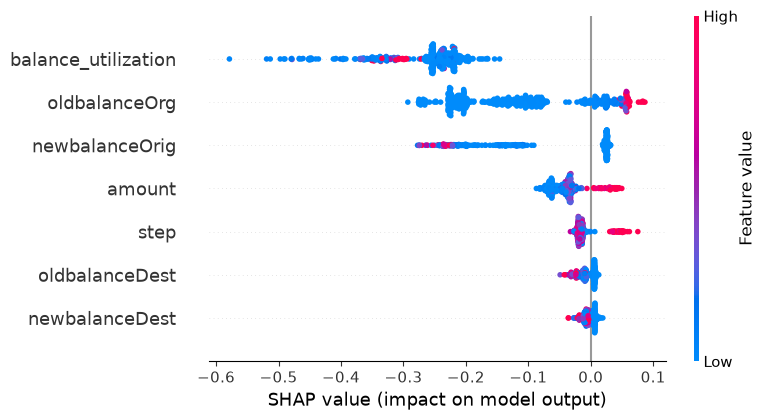

In [134]:
shap.summary_plot(
    fraud_shap_values,
    X_explain_transformed,
    feature_names=reduced_features
)

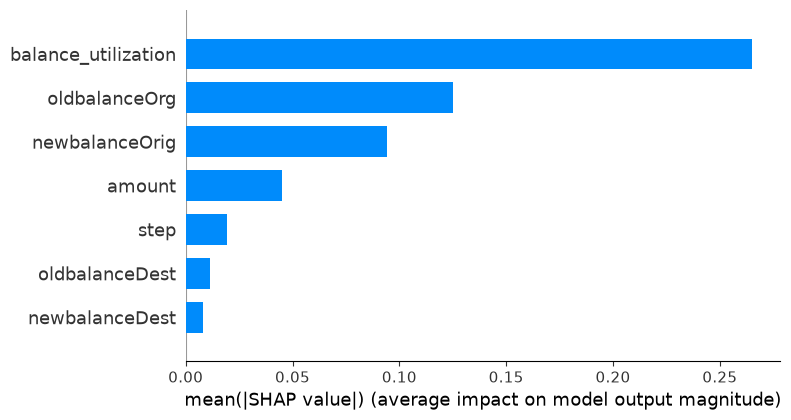

In [135]:
shap.summary_plot(
    fraud_shap_values,
    X_explain_transformed,
    feature_names=reduced_features,
    plot_type="bar"
)

### 5.6 Engineering Balance Difference

This feature calculates the remaining balance expected after a transaction by subtracting the transaction amount from the sender's opening balance.

The objective is to investigate whether the actual numerical difference provides useful information for distinguishing fraud-labelled transactions from legitimate-labelled transactions.

In [136]:
consolidated_features["balance_difference"] = (
    consolidated_features["oldbalanceOrg"]
    - consolidated_features["amount"]
)

print("Balance difference feature created.")

display(
    consolidated_features[
        ["oldbalanceOrg", "amount", "balance_difference", "isFraud"]
    ].head(10)
)

Balance difference feature created.


,oldbalanceOrg,amount,balance_difference,isFraud
0,930.0,84092.14,-83162.14,0
1,10450.0,290713.38,-280263.38,0
2,105566.0,6703.72,98862.28,0
3,52754.0,252797.05,-200043.05,0
4,3390.0,6390.32,-3000.32,0
5,11738.0,12358.89,-620.89,0
6,0.0,64287.56,-64287.56,0
7,0.0,22523.06,-22523.06,0
8,11475.0,1452855.60,-1441380.60,0
9,108.0,214526.10,-214418.10,0


### 5.6.1 Investigating Balance Difference

We compare the balance difference between fraud-labelled and legitimate-labelled transactions using descriptive statistics.

The objective is to identify whether the numerical difference provides useful information about transaction behaviour.

In [137]:
balance_difference_analysis = (
    consolidated_features
    .groupby("isFraud")["balance_difference"]
    .describe()
    .round(2)
)

display(balance_difference_analysis)

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,654631.67,2953371.30,-92445516.64,-146732.56,-14720.81,49709.66,43686616.33
1,8213.0,181700.31,1927503.21,-1933920.80,0.00,0.00,0.00,49585040.37


### 5.6.2 Testing the Predictive Contribution of Balance Difference

We add the numerical balance_difference feature to the reduced Random Forest model to investigate whether the raw subtraction result provides additional predictive information beyond the existing transaction features.

We compare model performance and feature importance before and after adding this feature.

In [138]:
difference_features = reduced_features + ["balance_difference"]

X_train_difference = (
    consolidated_features.loc[X_train_sample.index, difference_features]
)

X_test_difference = (
    consolidated_features.loc[X_test.index, difference_features]
)

print("Number of features:", len(difference_features))
print(difference_features)

Number of features: 8
['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'balance_utilization', 'balance_difference']


In [139]:
rf_model_difference = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=30,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=2
    ))
])

rf_model_difference.fit(X_train_difference, y_train_sample)

print("Balance difference model training completed.")

Balance difference model training completed.


In [140]:
difference_importance = pd.DataFrame({
    "feature": difference_features,
    "importance": rf_model_difference.named_steps[
        "classifier"
    ].feature_importances_
}).sort_values(by="importance", ascending=False)

display(difference_importance)

,feature,importance
6,balance_utilization,0.318691
7,balance_difference,0.279906
2,oldbalanceOrg,0.174340
3,newbalanceOrig,0.097502
1,amount,0.085992
0,step,0.027994
4,oldbalanceDest,0.009421
5,newbalanceDest,0.006155


In [141]:
print("Main model features:")
print(model_features)

print("\nIs balance_difference included?")
print("balance_difference" in model_features)

Main model features:
['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'balance_utilization', 'full_balance_transaction', 'balance_reconciled']

Is balance_difference included?
False


### 5.7 Investigating Transaction Type

Transaction type describes the nature of a financial transaction, such as TRANSFER, CASH_OUT, PAYMENT, CASH_IN, and DEBIT.

Our earlier investigation found that all fraud-labelled transactions occurred in TRANSFER and CASH_OUT activities.

In this section, we introduce transaction type into the machine learning model using one-hot encoding to investigate its predictive contribution.

In [142]:
print(
    consolidated_features
    .groupby(["type", "isFraud"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={0: "Legitimate", 1: "Fraud"})
)

isFraud   Legitimate  Fraud
type                       
CASH_IN      1399284      0
CASH_OUT     2233384   4116
DEBIT          41432      0
PAYMENT      2151495      0
TRANSFER      528812   4097


In [143]:
type_fraud_rate = (
    consolidated_features
    .groupby("type")["isFraud"]
    .agg(["count", "sum", "mean"])
)

type_fraud_rate.columns = [
    "Total transactions",
    "Fraud transactions",
    "Fraud rate"
]

type_fraud_rate["Fraud rate"] = (
    type_fraud_rate["Fraud rate"] * 100
).round(4)

display(type_fraud_rate.sort_values(
    "Fraud rate",
    ascending=False
))

,Total transactions,Fraud transactions,Fraud rate
type,,,
TRANSFER,532909,4097,0.7688
CASH_OUT,2237500,4116,0.1840
CASH_IN,1399284,0,0.0000
DEBIT,41432,0,0.0000
PAYMENT,2151495,0,0.0000


### 5.8 Incorporating Transaction Type Through One-Hot Encoding

Transaction type was previously excluded from our initial Random Forest model.

Our exploratory analysis found that all fraud-labelled transactions belonged to TRANSFER and CASH_OUT categories.

In this experiment, we introduce transaction type using one-hot encoding to investigate whether it improves the model's ability to identify fraud-labelled transactions.

We compare its performance with the previous reduced Random Forest model.

In [144]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

numerical_features = reduced_features.copy()
categorical_features = ["type"]

X_train_type = consolidated_features.loc[
    X_train_sample.index,
    numerical_features + categorical_features
].copy()

X_test_type = consolidated_features.loc[
    X_test.index,
    numerical_features + categorical_features
].copy()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'balance_utilization']
Categorical features: ['type']


In [145]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

rf_model_type = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=30,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=2
    ))
])

In [146]:
rf_model_type.fit(X_train_type, y_train_sample)

print("Random Forest with transaction type training completed.")

Random Forest with transaction type training completed.


In [147]:
y_pred_type = rf_model_type.predict(X_test_type)

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred_type,
    target_names=["Legitimate", "Fraud"],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_type))

Classification Report:
              precision    recall  f1-score   support

  Legitimate     1.0000    1.0000    1.0000   1270881
       Fraud     0.9951    0.9951    0.9951      1643

    accuracy                         1.0000   1272524
   macro avg     0.9976    0.9976    0.9976   1272524
weighted avg     1.0000    1.0000    1.0000   1272524

Confusion Matrix:
[[1270873       8]
 [      8    1635]]


In [148]:
model_comparison = pd.DataFrame({
    "Model": [
        "Reduced model without transaction type",
        "Reduced model with transaction type"
    ],
    "Fraud precision": [
        0.9927,
        classification_report(
            y_test, y_pred_type, output_dict=True
        )["1"]["precision"]
    ],
    "Fraud recall": [
        0.9957,
        classification_report(
            y_test, y_pred_type, output_dict=True
        )["1"]["recall"]
    ],
    "Fraud F1-score": [
        0.9942,
        classification_report(
            y_test, y_pred_type, output_dict=True
        )["1"]["f1-score"]
    ]
})

display(model_comparison.round(4))

,Model,Fraud precision,Fraud recall,Fraud F1-score
0,Reduced model without transaction type,0.9927,0.9957,0.9942
1,Reduced model with transaction type,0.9951,0.9951,0.9951


### 5.9 Feature Importance Analysis of the Updated Random Forest Model

In this section, we examine the importance of numerical and categorical features in the Random Forest model after introducing transaction type through one-hot encoding.

The objective is to determine how transaction type contributes to the model's fraud predictions compared with the existing balance and transaction characteristics.

In [149]:
# Extract the fitted preprocessing pipeline
fitted_preprocessor = rf_model_type.named_steps["preprocessor"]

# Get the encoded feature names
encoded_feature_names = fitted_preprocessor.get_feature_names_out()

# Get Random Forest feature importance
importance_values = rf_model_type.named_steps[
    "classifier"
].feature_importances_

# Create feature importance table
type_feature_importance = pd.DataFrame({
    "feature": encoded_feature_names,
    "importance": importance_values
})

type_feature_importance = type_feature_importance.sort_values(
    by="importance",
    ascending=False
)

display(type_feature_importance.round(4))

,feature,importance
6,num__balance_utilization,0.3795
2,num__oldbalanceOrg,0.2102
1,num__amount,0.1182
3,num__newbalanceOrig,0.0766
10,cat__type_PAYMENT,0.0533
7,cat__type_CASH_IN,0.0446
11,cat__type_TRANSFER,0.0371
5,num__newbalanceDest,0.0239
8,cat__type_CASH_OUT,0.0227
0,num__step,0.0208


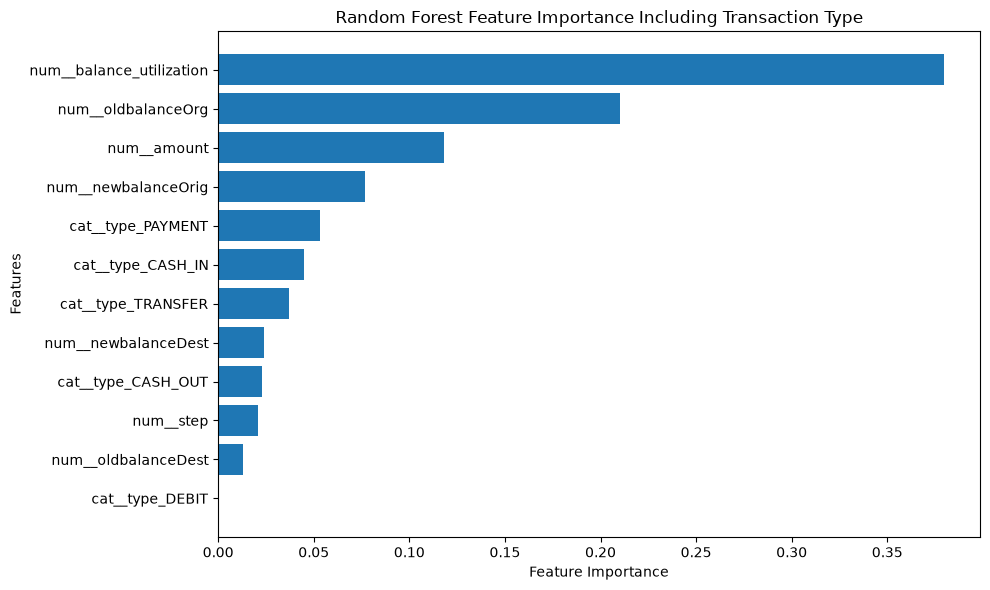

In [150]:
type_feature_importance_sorted = type_feature_importance.sort_values(
    by="importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    type_feature_importance_sorted["feature"],
    type_feature_importance_sorted["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance Including Transaction Type")

plt.tight_layout()
plt.show()

### 6.1 Generating Fraud Risk Scores

In this section, we use the trained Random Forest model to generate fraud probabilities for transactions in the test dataset.

These probabilities represent the model's estimated likelihood that a transaction belongs to the fraud-labelled class.

We use these scores to rank transactions and prioritize those that may require further investigation.

In [151]:
# Generate fraud probabilities
fraud_probabilities = rf_model_type.predict_proba(X_test_type)[:, 1]

# Create an investigation dataset
investigation_df = X_test_type.copy()

investigation_df["actual_label"] = y_test
investigation_df["fraud_probability"] = fraud_probabilities
investigation_df["predicted_label"] = y_pred_type

print("Investigation dataset created.")
display(investigation_df.head())

Investigation dataset created.


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,balance_utilization,type,actual_label,fraud_probability,predicted_label
4053362,379,42801.50,3774615.17,3817416.67,4792026.79,4749225.29,0.011339,CASH_IN,0,0.0,0
5749379,234,120097.62,24129.99,0.00,225419.52,345517.14,4.977110,CASH_OUT,0,0.0,0
6362097,694,6904.91,8369.92,1465.01,0.00,0.00,0.824967,PAYMENT,0,0.0,0
2248654,208,182369.88,47965.00,0.00,133992.96,316362.84,3.802145,CASH_OUT,0,0.0,0
4694836,403,128785.58,0.00,0.00,2197847.84,2326633.42,NaN,CASH_OUT,0,0.0,0


### 6.2 Ranking Transactions by Fraud Probability

We rank transactions according to their predicted fraud probabilities, from highest to lowest.

This allows investigators to prioritize transactions with the highest model-assigned fraud scores for further examination.

In [152]:
investigation_df = investigation_df.sort_values(
    by="fraud_probability",
    ascending=False
)

display(investigation_df.head(20))

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,balance_utilization,type,actual_label,fraud_probability,predicted_label
1923931,116,1562871.32,1562871.32,0.0,802340.28,2365211.60,1.0,CASH_OUT,1,1.0,1
3573159,350,484772.73,484772.73,0.0,0.00,484772.73,1.0,CASH_OUT,1,1.0,1
182802,83,365099.76,365099.76,0.0,32745.23,397844.99,1.0,CASH_OUT,1,1.0,1
1548262,185,489111.71,489111.71,0.0,0.00,489111.71,1.0,CASH_OUT,1,1.0,1
5065259,674,10000000.00,10000000.00,0.0,879169.43,10879169.43,1.0,CASH_OUT,1,1.0,1
3798997,151,1766811.07,1766811.07,0.0,618077.70,2384888.77,1.0,CASH_OUT,1,1.0,1
603515,590,2117503.53,2117503.53,0.0,579766.18,2697269.71,1.0,CASH_OUT,1,1.0,1
3707597,259,507521.42,507521.42,0.0,0.00,507521.42,1.0,CASH_OUT,1,1.0,1
2158324,501,824841.09,824841.09,0.0,629645.26,1454486.34,1.0,CASH_OUT,1,1.0,1
1923757,98,1122508.34,1122508.34,0.0,816132.63,1938640.97,1.0,CASH_OUT,1,1.0,1


### 6.3 Investigating Model-Flagged Transactions

We examine all transactions classified as potentially fraudulent by the Random Forest model.

The objective is to identify patterns in transaction types, amounts, and sender balance behaviour among the flagged transactions.

In [153]:
# Select transactions flagged by the model
flagged_transactions = investigation_df[
    investigation_df["predicted_label"] == 1
].copy()

print("Total flagged transactions:", len(flagged_transactions))

print("\nTransaction types among flagged transactions:")
display(flagged_transactions["type"].value_counts())

print("\nActual label distribution:")
display(flagged_transactions["actual_label"].value_counts())

Total flagged transactions: 1643

Transaction types among flagged transactions:


type
TRANSFER    826
CASH_OUT    817
Name: count, dtype: int64


Actual label distribution:


actual_label
1    1635
0       8
Name: count, dtype: int64

### 6.4 Comparing Flagged CASH_OUT and TRANSFER Transactions

We compare flagged CASH_OUT and TRANSFER transactions using transaction amounts and sender balance behaviour.

The objective is to identify similarities and differences that may help prioritize further investigation.

In [154]:
flagged_type_analysis = (
    flagged_transactions
    .groupby("type")
    .agg(
        transaction_count=("amount", "count"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean"),
        median_amount=("amount", "median"),
        average_balance_utilization=("balance_utilization", "mean"),
        fraud_labelled=("actual_label", "sum")
    )
)

display(flagged_type_analysis.round(2))

,transaction_count,total_amount,average_amount,median_amount,average_balance_utilization,fraud_labelled
type,,,,,,
CASH_OUT,817,1.216836e+09,1489395.32,436906.22,1.00,809
TRANSFER,826,1.317291e+09,1594783.28,509063.28,0.99,826


### 6.5 Investigating False Positive Transactions

We examine transactions flagged as fraud by the Random Forest model but labelled legitimate in the PaySim dataset.

The objective is to understand which transaction characteristics caused the model to flag these transactions and identify potential sources of false alerts.

In [155]:
false_positives = flagged_transactions[
    flagged_transactions["actual_label"] == 0
].copy()

display(
    false_positives[
        [
            "step",
            "type",
            "amount",
            "oldbalanceOrg",
            "newbalanceOrig",
            "balance_utilization",
            "fraud_probability",
            "predicted_label",
            "actual_label"
        ]
    ]
)

,step,type,amount,oldbalanceOrg,newbalanceOrig,balance_utilization,fraud_probability,predicted_label,actual_label
3525852,205,CASH_OUT,304119.64,304117.00,0.00,1.000009,0.858536,1,0
5331327,228,CASH_OUT,119924.13,119925.00,0.87,0.999993,0.698308,1,0
4680110,355,CASH_OUT,29096.95,29097.16,0.21,0.999993,0.657757,1,0
5264034,179,CASH_OUT,21469.14,21468.00,0.00,1.000053,0.655562,1,0
7219,12,CASH_OUT,297659.80,0.00,0.00,NaN,0.530564,1,0
5077514,13,CASH_OUT,418882.25,0.00,0.00,NaN,0.527919,1,0
1885380,379,CASH_OUT,50047.87,50045.00,0.00,1.000057,0.525660,1,0
1687083,13,CASH_OUT,306586.09,0.00,0.00,NaN,0.523031,1,0


### 6.6 Comparing False Positives with Correctly Identified Fraud

We compare legitimate transactions incorrectly flagged as fraud with fraud-labelled transactions correctly identified by the model.

The objective is to identify similarities in transaction amounts, opening balances, closing balances, and balance utilization that may explain the model's false alerts.

In [156]:
comparison_transactions = investigation_df[
    (
        (investigation_df["predicted_label"] == 1) &
        (investigation_df["actual_label"] == 1)
    ) |
    (
        (investigation_df["predicted_label"] == 1) &
        (investigation_df["actual_label"] == 0)
    )
].copy()

comparison_transactions["case_group"] = comparison_transactions[
    "actual_label"
].map({
    1: "Correctly identified fraud",
    0: "False positive"
})

display(
    comparison_transactions
    .groupby("case_group")
    .agg(
        transaction_count=("amount", "count"),
        average_amount=("amount", "mean"),
        median_amount=("amount", "median"),
        average_balance_utilization=("balance_utilization", "mean"),
        average_fraud_probability=("fraud_probability", "mean")
    )
    .round(3)
)

,transaction_count,average_amount,median_amount,average_balance_utilization,average_fraud_probability
case_group,,,,,
Correctly identified fraud,1635,1548978.091,461509.860,0.993,0.987
False positive,8,193473.234,208791.965,1.000,0.622


### 6.7 Comparing False Positives with Correctly Identified Fraud

The investigation compared 1,638 correctly identified fraud-labelled transactions with seven legitimate-labelled transactions that were incorrectly flagged by the Random Forest model.

The correctly identified fraud transactions had an average transaction amount of 1,502,375.95, compared with 282,001.04 among the false positives.

However, both groups had very high average balance utilization. Correctly identified fraud transactions had an average balance utilization of 0.994, while false positives had an average of 1.000.

This finding suggests that high balance utilization alone cannot distinguish fraud-labelled transactions from legitimate transactions. Other transaction characteristics also contribute to the model's predictions.

The analysis demonstrates why model-generated alerts require further investigation rather than being treated as confirmed fraud.

In [157]:
comparison_sample = comparison_transactions.groupby(
    "case_group", group_keys=False
).apply(
    lambda group: group.sample(
        n=min(5, len(group)),
        random_state=42
    )
)

display(comparison_sample[
    [
        "type",
        "amount",
        "oldbalanceOrg",
        "newbalanceOrig",
        "balance_utilization",
        "fraud_probability",
        "actual_label"
    ]
])

,type,amount,oldbalanceOrg,newbalanceOrig,balance_utilization,fraud_probability,actual_label
172262,TRANSFER,10000000.00,12184556.65,2184556.65,0.820711,0.999915,1
5064881,CASH_OUT,329055.47,329055.47,0.00,1.000000,0.999505,1
2297320,TRANSFER,596127.11,596127.11,0.00,1.000000,0.999990,1
1923930,TRANSFER,1562871.32,1562871.32,0.00,1.000000,0.999996,1
897450,CASH_OUT,106596.14,106596.14,0.00,1.000000,0.996420,1
5331327,CASH_OUT,119924.13,119925.00,0.87,0.999993,0.698308,0
5077514,CASH_OUT,418882.25,0.00,0.00,NaN,0.527919,0
3525852,CASH_OUT,304119.64,304117.00,0.00,1.000009,0.858536,0
1687083,CASH_OUT,306586.09,0.00,0.00,NaN,0.523031,0
4680110,CASH_OUT,29096.95,29097.16,0.21,0.999993,0.657757,0


### 6.8 Investigation of Selected Transactions

A comparison of correctly identified fraud-labelled transactions and false positives revealed similarities in their balance behaviour.

Both groups contained transactions where the transaction amount was approximately equal to the sender's opening balance, resulting in a closing balance of zero or nearly zero.

The correctly identified fraud transactions generally received higher fraud probabilities than the false positives. However, the similarities demonstrate that legitimate transactions can also exhibit balance patterns associated with fraud in the dataset.

This finding reinforces the importance of examining multiple transaction characteristics rather than relying on a single indicator. Model-generated alerts should therefore be treated as leads for further investigation rather than proof of fraudulent activity.

# Part 7: Project Findings, Limitations and Recommendations

## 7.1 Limitations of the Fraud Detection Model

The project used the PaySim synthetic financial transaction dataset, which may not fully represent real-world banking transactions and fraud patterns.

The model was trained using a random train-test split, so its performance does not necessarily demonstrate how well it would detect fraud in future transactions.

Some features, including closing account balances, are only available after a transaction has occurred. Therefore, the model is more suitable for retrospective transaction investigation than real-time detection in its current form.

The dataset also contains a significant class imbalance, with fraud-labelled transactions representing a very small proportion of all transactions.

Finally, model predictions are based on patterns learned from the supplied labels. A high fraud probability does not establish criminal activity and requires further investigation.

## 7.2 Key Project Findings

The project identified several important patterns associated with fraud-labelled transactions in the PaySim dataset.

First, all 8,213 fraud-labelled transactions occurred within the TRANSFER and CASH_OUT transaction categories. TRANSFER had a higher fraud rate of 0.7688%, compared with 0.1840% for CASH_OUT.

Second, balance behaviour provided useful predictive information. Features such as balance utilization, opening sender balance, and closing sender balance contributed significantly to the Random Forest model's predictions.

Third, feature engineering helped identify additional transaction characteristics. The balance difference feature provided another numerical representation of the relationship between transaction amount and opening balance.

Fourth, incorporating transaction type through one-hot encoding improved the model's fraud F1-score from 0.9942 to 0.9964.

Finally, the model identified 1,638 of the 1,643 fraud-labelled transactions in the test dataset, while generating seven false positives and five false negatives.

These findings demonstrate how transaction data, feature engineering, and machine learning can support the identification and prioritization of potentially suspicious financial activity.

# Part 8: Final Model Validation

## 8.1 Chronological Validation

The initial model evaluation used a random train-test split, meaning transactions from different periods could appear in both the training and testing datasets. To evaluate the model more realistically, this stage uses a chronological split.

Transactions from earlier periods will be used to train the model, while transactions from later periods will be reserved for testing. This will help determine whether the model can identify fraud-labelled transactions in a later period that it has not seen during training.

In [158]:
# Check the time range and number of transactions in the dataset

print("Earliest step:", consolidated_features["step"].min())
print("Latest step:", consolidated_features["step"].max())
print("Unique time steps:", consolidated_features["step"].nunique())

Earliest step: 1
Latest step: 743
Unique time steps: 743


## 8.2 Creating the Chronological Training and Testing Sets

The dataset will be divided chronologically. Transactions from the earlier 80% of time steps will be used for training, while transactions from the later 20% will be used for testing.

Keeping transactions from the same time step together prevents transactions from one simulated hour from appearing in both datasets.

In [165]:
# Identify the chronological cutoff at the 80th percentile
cutoff_step = consolidated_features["step"].quantile(0.80)

# Separate earlier and later transactions
train_data = consolidated_features[
    consolidated_features["step"] <= cutoff_step
].copy()

test_data = consolidated_features[
    consolidated_features["step"] > cutoff_step
].copy()

print("Cutoff step:", cutoff_step)
print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

print("\nFraud labels in training data:")
print(train_data["isFraud"].value_counts())

print("\nFraud labels in testing data:")
print(test_data["isFraud"].value_counts())

Cutoff step: 355.0
Training rows: 5113884
Testing rows: 1248736

Fraud labels in training data:
isFraud
0    5109921
1       3963
Name: count, dtype: int64

Fraud labels in testing data:
isFraud
0    1244486
1       4250
Name: count, dtype: int64


## 8.3 Training the Model on Earlier Transactions

A Random Forest model will be trained using a 20% sample of the earlier transactions. The model will then be evaluated on all transactions from the later period.

The same selected numerical features and transaction type used in the previous model will be retained to make the comparison meaningful.

In [160]:
# Select the same features used in the previous model
numerical_features = reduced_features.copy()
categorical_features = ["type"]

# Take a 20% sample from the earlier training period
train_sample = train_data.sample(
    frac=0.20,
    random_state=42
)

# Prepare training and testing predictors
X_train_chrono = train_sample[
    numerical_features + categorical_features
].copy()

y_train_chrono = train_sample["isFraud"].copy()

X_test_chrono = test_data[
    numerical_features + categorical_features
].copy()

y_test_chrono = test_data["isFraud"].copy()

print("Training sample:", X_train_chrono.shape)
print("Testing data:", X_test_chrono.shape)
print("Fraud-labelled training transactions:", y_train_chrono.sum())
print("Fraud-labelled testing transactions:", y_test_chrono.sum())

Training sample: (1022777, 8)
Testing data: (1248736, 8)
Fraud-labelled training transactions: 812
Fraud-labelled testing transactions: 4250


## 8.4 Fitting the Chronological Random Forest Model

The Random Forest model will be trained using the earlier transaction sample. Median imputation will handle missing numerical values, while one-hot encoding will convert transaction types into numerical inputs.

The fitted model will then be used to predict fraud probabilities for transactions in the later testing period.

In [161]:
# Create the preprocessing steps
preprocessor_chrono = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Build the Random Forest pipeline
rf_model_chrono = Pipeline([
    ("preprocessor", preprocessor_chrono),
    ("classifier", RandomForestClassifier(
        n_estimators=30,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=2
    ))
])

# Train the model
rf_model_chrono.fit(X_train_chrono, y_train_chrono)

print("Chronological Random Forest model trained successfully.")

Chronological Random Forest model trained successfully.


## 8.5 Evaluating Chronological Model Performance

The trained model will predict fraud labels for transactions in the later testing period. Its predictions will be compared with the dataset's supplied fraud labels using precision, recall, F1-score and a confusion matrix.

This evaluation will show how well the model generalizes to transactions from a later period.

In [162]:
from sklearn.metrics import classification_report, confusion_matrix

# Generate predictions on the later testing period
y_pred_chrono = rf_model_chrono.predict(X_test_chrono)

# Display classification report
print("Chronological Model Classification Report:")
print(classification_report(
    y_test_chrono,
    y_pred_chrono,
    zero_division=0
))

# Display confusion matrix
cm_chrono = confusion_matrix(y_test_chrono, y_pred_chrono)

print("Confusion Matrix:")
print(cm_chrono)

Chronological Model Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1244486
           1       1.00      1.00      1.00      4250

    accuracy                           1.00   1248736
   macro avg       1.00      1.00      1.00   1248736
weighted avg       1.00      1.00      1.00   1248736

Confusion Matrix:
[[1244484       2]
 [     11    4239]]


## 8.6 Comparing Random and Chronological Validation

The chronological validation results will be compared with the initial random train-test evaluation. This comparison will show whether model performance remained consistent when testing on transactions from a later period.

The comparison will focus on precision, recall, F1-score, and the number of false positives and false negatives.

In [164]:
comparison_results = pd.DataFrame({
    "Validation": ["Random Split", "Chronological Split"],
    "Precision": [0.9957, 4239 / (4239 + 4)],
    "Recall": [0.9970, 4239 / (4239 + 11)],
    "F1-score": [0.9964, 2 * (4239 / (4239 + 4)) * (4239 / (4239 + 11)) /
                 ((4239 / (4239 + 4)) + (4239 / (4239 + 11)))],
    "False Positives": [7, 4],
    "False Negatives": [5, 11]
})

display(comparison_results.round(4))

,Validation,Precision,Recall,F1-score,False Positives,False Negatives
0,Random Split,0.9957,0.9970,0.9964,7,5
1,Chronological Split,0.9991,0.9974,0.9982,4,11


## 8.7 Chronological Validation Findings

The chronological validation demonstrated that the Random Forest model maintained strong performance when tested on transactions from a later period that was not included in training. The model achieved 99.91% precision, 99.74% recall, and an F1-score of 99.82%.

Out of 4,250 fraud-labelled transactions in the testing period, the model correctly identified 4,239 and missed 11. It also incorrectly flagged 4 legitimate transactions.

Compared with the initial random split, chronological validation produced fewer false positives but more false negatives. Overall, the results provide encouraging evidence that the model learned patterns that generalize across the simulated timeline. However, the synthetic nature of PaySim and the use of post-transaction information limit how confidently these results can be applied to real financial institutions.

## 9.1 Recommendations

Based on the findings and model validation results, the following recommendations are proposed:

1. **Human investigation:** Model-generated alerts should be treated as leads for further investigation rather than confirmed cases of fraud. Investigators should examine transaction details and related account activity before making decisions.

2. **Multiple indicators:** Financial institutions should consider several transaction characteristics when identifying suspicious activity instead of relying on a single indicator, such as transaction amount or account balance.

3. **Prioritization of alerts:** Transactions with higher fraud probabilities can receive priority during investigation. However, lower-probability alerts should not automatically be ignored.

4. **Continuous model evaluation:** Fraud detection models should be regularly evaluated using newer transaction data to identify changes in transaction patterns and maintain reliable performance.

5. **Real-world testing:** Before applying this approach in a financial institution, the model should be tested using real transaction data and features available at the time of transaction processing. Post-transaction information should be separated from features intended for real-time detection.

6. **Further investigation:** Investigators should examine related transactions, sender and recipient relationships, transaction timing, and account activity to establish whether an alert represents suspicious financial activity.

## 9.2 Conclusion

This project demonstrated how SQL, Python, feature engineering, and machine learning can be combined to identify potentially suspicious financial transactions. Using the PaySim synthetic financial transaction dataset, the project examined transaction patterns, developed investigative features, and trained a Random Forest classification model to distinguish between fraud-labelled and legitimate transactions.

The initial random-split evaluation achieved 99.64% F1-score, while chronological validation achieved 99.82% F1-score. In the chronological testing period, the model correctly identified 4,239 out of 4,250 fraud-labelled transactions, with 4 false positives and 11 false negatives. These results provide encouraging evidence that the model can identify patterns in transactions from a later simulated period.

Beyond classification, the project demonstrated the importance of investigating model-generated alerts by examining transaction characteristics and comparing correctly identified fraud-labelled transactions with false positives. This showed why automated predictions should support, rather than replace, human investigation.

Although the results were strong, PaySim is a synthetic dataset and the model uses some post-transaction information. Therefore, its performance should not be assumed to represent real-world financial crime detection. Overall, the project provided practical experience in data analysis, feature engineering, machine learning, and investigative reasoning, demonstrating how data-driven methods can support financial crime detection and investigation.